# Análisis de Temporada — Chaco For Ever
Scrapea los partidos pendientes y genera el análisis completo de la temporada:
tabla de resultados, gráficos y el informe narrativo con Claude.

In [1]:
import os, sys

# Recarga automática de módulos src/ al editarlos (sin reiniciar kernel)
%load_ext autoreload
%autoreload 2

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd()
sys.path.insert(0, PROJECT_ROOT)

import config
from src.scraping.chaco_scraper import SofascoreClient, fetch_match, load_matches, _match_done
from src.analysis.season import (
    build_season_table, season_stats, season_player_stats,
    top_scorers, most_used_players, substitution_analysis,
    shared_minutes_network, assists_network, load_calendar, is_home_match,
    threat_by_situation, xg_by_score_state, final_third_touches,
    markov_game_state, eigenvector_centrality_network, shot_entropy,
    build_defensive_survival_dataset, fit_defensive_hazard_model,
)
from src.analysis.players import player_pool, player_percentiles, compare_players
from src.visualization.season import (
    plot_shotmap, plot_shotmap_4grid, plot_season_points, plot_xg_season,
    plot_top_players, save_fig, plot_shared_minutes_network,
    plot_recent_form, plot_home_away_panel, plot_discipline,
    plot_load_calendar, plot_assists_network,
    plot_threat_by_situation, plot_xg_by_score_state, plot_final_third_touches,
    plot_markov_transitions, plot_eigen_centrality, plot_shot_entropy,
    plot_defensive_hazard,
)
from src.visualization.players import plot_player_pizza, plot_players_radar
from src.reports.season import season_report, player_season_report

# Helper para MOSTRAR un gráfico guardado inline (save_fig cierra la figura).
from IPython.display import Image, display
def show(path):
    if path and os.path.exists(path):
        display(Image(filename=path))

# ============================================================
# CONFIGURAR ACÁ
SEASON          = '2026'   # temporada a cerrar (datos 100% bajados)
SCRAPE_MISSING  = True    # los 34 ya están; no hay que scrapear nada
INCLUDE_HEATMAPS = True   # True si querés bajar heatmaps al scrapear pendientes
GENERATE_REPORT = False    # informe con modelo GRATIS de NVIDIA (key en .env)
# ============================================================

BASE_DIR    = config.season_data_dir(SEASON)
PLOTS_DIR   = config.season_plots_dir(SEASON)
REPORTS_DIR = config.season_reports_dir(SEASON)
os.makedirs(PLOTS_DIR,   exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

MATCHES = load_matches(SEASON)
print(f'Temporada : {SEASON}')
print(f'Partidos  : {len(MATCHES)}')
print(f'Datos en  : {BASE_DIR}')

Temporada : 2026
Partidos  : 20
Datos en  : c:\Users\luart\OneDrive\Escritorio\Chaco For Ever Analisis\data\temporadas\2026\partidos


## 1. Verificar cobertura y scrapear pendientes

In [2]:
pendientes = []
for mk in MATCHES:
    match_dir = os.path.join(BASE_DIR, mk)
    if _match_done(match_dir):
        print(f'✅ {mk}')
    else:
        print(f'❌ {mk}')
        pendientes.append(mk)

print(f'\nPendientes: {len(pendientes)}/{len(MATCHES)}')

✅ 2026-02-14_vs_acassuso_a
✅ 2026-02-21_vs_san_telmo_h
✅ 2026-02-28_vs_san_miguel_a
✅ 2026-03-14_vs_deportivo_moron_a
✅ 2026-03-21_vs_godoy_cruz_h
✅ 2026-03-27_vs_gimnasia_de_jujuy_h
✅ 2026-04-05_vs_los_andes_a
✅ 2026-04-12_vs_all_boys_h
✅ 2026-04-19_vs_estudiantes_caseros_a
✅ 2026-04-26_vs_mitre_h
✅ 2026-05-03_vs_almirante_brown_a
✅ 2026-05-10_vs_ciudad_de_bolivar_h
✅ 2026-05-18_vs_defensores_de_belgrano_a
✅ 2026-05-24_vs_deportivo_madryn_h
✅ 2026-05-31_vs_central_norte_a
✅ 2026-06-07_vs_ferro_carril_oeste_h
✅ 2026-06-14_vs_racing_de_cordoba_a
✅ 2026-06-20_vs_colon_h
✅ 2026-07-07_vs_acassuso_h
✅ 2026-07-11_vs_san_telmo_a

Pendientes: 0/20


In [3]:
import time, random

# Reconstruye lista al momento de correr (no depende de la celda anterior)
pendientes_now = [
    mk for mk in MATCHES
    if not _match_done(os.path.join(BASE_DIR, mk))
]

if not SCRAPE_MISSING or not pendientes_now:
    print(f'{'Nada que scrapear.' if not pendientes_now else 'SCRAPE_MISSING=False, saltando scraping.'}')
else:
    print(f'Scrapeando {len(pendientes_now)} partidos...\n')
    with SofascoreClient(headless=False) as client:
        for i, mk in enumerate(pendientes_now):
            print(f'[{i+1}/{len(pendientes_now)}] {mk}')
            try:
                res = fetch_match(client, mk, MATCHES[mk], BASE_DIR,
                                  include_heatmaps=INCLUDE_HEATMAPS)
                for ep, ok in res.items():
                    print(f'   {"OK" if ok else "--"} {ep}')
            except Exception as e:
                print(f'   ERROR: {e}')
            if i < len(pendientes_now) - 1:
                time.sleep(random.uniform(config.MIN_DELAY, config.MAX_DELAY))

Nada que scrapear.


## 2. Tabla de resultados de la temporada

In [4]:
# Solo incluir partidos que tienen datos
match_keys_with_data = [
    mk for mk in MATCHES
    if _match_done(os.path.join(BASE_DIR, mk))
]

season_df = build_season_table(match_keys_with_data, BASE_DIR)
stats     = season_stats(season_df)

print(f"Partidos: {stats['partidos']}  |  {stats['victorias']}V-{stats['empates']}E-{stats['derrotas']}D  |  {stats['puntos']} pts")
print(f"Goles: {stats['goles_favor']} a favor / {stats['goles_contra']} en contra")
print(f"xG: {stats['xg_favor']} favor / {stats['xg_contra']} contra")
print(f"Local: {stats['rendimiento_local']}  |  Visitante: {stats['rendimiento_visitante']}")
print()
print(season_df[['date','opponent','venue','result','chaco_goals','rival_goals']].to_string(index=False))

Partidos: 20  |  3V-7E-10D  |  16 pts
Goles: 17 a favor / 26 en contra
xG: 17.3 favor / 19.59 contra
Local: 2V-4E-4D  |  Visitante: 1V-3E-6D

      date               opponent     venue result  chaco_goals  rival_goals
2026-02-14               Acassuso Visitante      L            0            2
2026-02-21              San Telmo     Local      D            2            2
2026-02-28             San Miguel Visitante      L            0            2
2026-03-14        Deportivo Moron Visitante      L            2            3
2026-03-21             Godoy Cruz     Local      D            1            1
2026-03-27      Gimnasia De Jujuy     Local      L            1            2
2026-04-05              Los Andes Visitante      L            0            2
2026-04-12               All Boys     Local      W            2            0
2026-04-19    Estudiantes Caseros Visitante      D            0            0
2026-04-26                  Mitre     Local      D            1            1
2026-05-03 

## 3. Estadísticas de jugadores

In [5]:
player_df = season_player_stats(match_keys_with_data, BASE_DIR)

print('=== Goleadores ===')
print(top_scorers(player_df).to_string(index=False))
print('\n=== Más utilizados ===')
print(most_used_players(player_df).to_string(index=False))

=== Goleadores ===
      player  goles  xg_total  partidos
L. Marinucci      4     2.473        15
  G. Pacheco      3     2.929        19
M. S. Romero      3     2.310         2
 I. Enriquez      2     2.345        19
    E. Gaggi      2     0.482         4

=== Más utilizados ===
       player  partidos  titularidades  minutos  rating_promedio
    D. Valdez        19             19   1685.0             6.75
     A. Luque        20             19   1645.0             6.75
   M. Silvera        17             15   1350.0             6.87
    B. Nievas        19             16   1276.0             6.73
   G. Pacheco        19             14   1263.0             6.82
    N. Caprio        20             13   1214.0             7.16
  I. Enriquez        19             11   1047.0             6.63
   J. Carrizo        18             13   1018.0             6.48
 L. Marinucci        15             12   1015.0             7.09
     R. Garay        16             10    938.0             6.81
  

## 4. Gráficos de temporada

In [6]:
import matplotlib
matplotlib.use('Agg')

fig = plot_season_points(season_df)
save_fig(fig, os.path.join(PLOTS_DIR, 'puntos_acumulados.png'))
print('✅ puntos_acumulados.png')

fig = plot_xg_season(season_df)
if fig:
    save_fig(fig, os.path.join(PLOTS_DIR, 'xg_temporada.png'))
    print('✅ xg_temporada.png')

if not player_df.empty:
    fig = plot_top_players(player_df, metric='minutos', top_n=15)
    save_fig(fig, os.path.join(PLOTS_DIR, 'top_minutos.png'))
    print('✅ top_minutos.png')

    # Rating: filtramos por minutos mínimos (un rating alto con poquísimos
    # minutos engaña) y arrancamos el eje cerca del mínimo para diferenciar.
    RATING_MIN_MIN = 600
    rating_df = player_df[player_df['minutos'] >= RATING_MIN_MIN].dropna(subset=['rating_promedio'])
    if not rating_df.empty:
        xmin = max(4.0, float(rating_df['rating_promedio'].min()) - 0.3)
        fig = plot_top_players(rating_df, metric='rating_promedio', top_n=15, xmin=xmin)
        save_fig(fig, os.path.join(PLOTS_DIR, 'top_rating.png'))
        print(f'✅ top_rating.png ({len(rating_df)} jugadores con {RATING_MIN_MIN}+ min)')

# Shotmap acumulado de la temporada: 4 paneles (gol / atajada / desviado / bloqueado),
# sin números ni detalle de jugadas. Tamaño del punto proporcional al xG.
import pandas as pd
all_shots = []
for mk in match_keys_with_data:
    sp = os.path.join(BASE_DIR, mk, 'shotmap_clean.csv')
    from src.analysis.season import is_home_match
    if os.path.exists(sp):
        df_s = pd.read_csv(sp)
        home_match = is_home_match(mk)
        all_shots.append(df_s[df_s['isHome'] == home_match])

if all_shots:
    df_all_shots = pd.concat(all_shots, ignore_index=True)
    fig = plot_shotmap_4grid(df_all_shots, team_label='Chaco For Ever',
                             title=f'Distribución de Tiros – Temporada {SEASON}')
    save_fig(fig, os.path.join(PLOTS_DIR, 'shotmap_temporada.png'))
    print('✅ shotmap_temporada.png')

✅ puntos_acumulados.png
✅ xg_temporada.png
✅ top_minutos.png
✅ top_rating.png (13 jugadores con 600+ min)
✅ shotmap_temporada.png


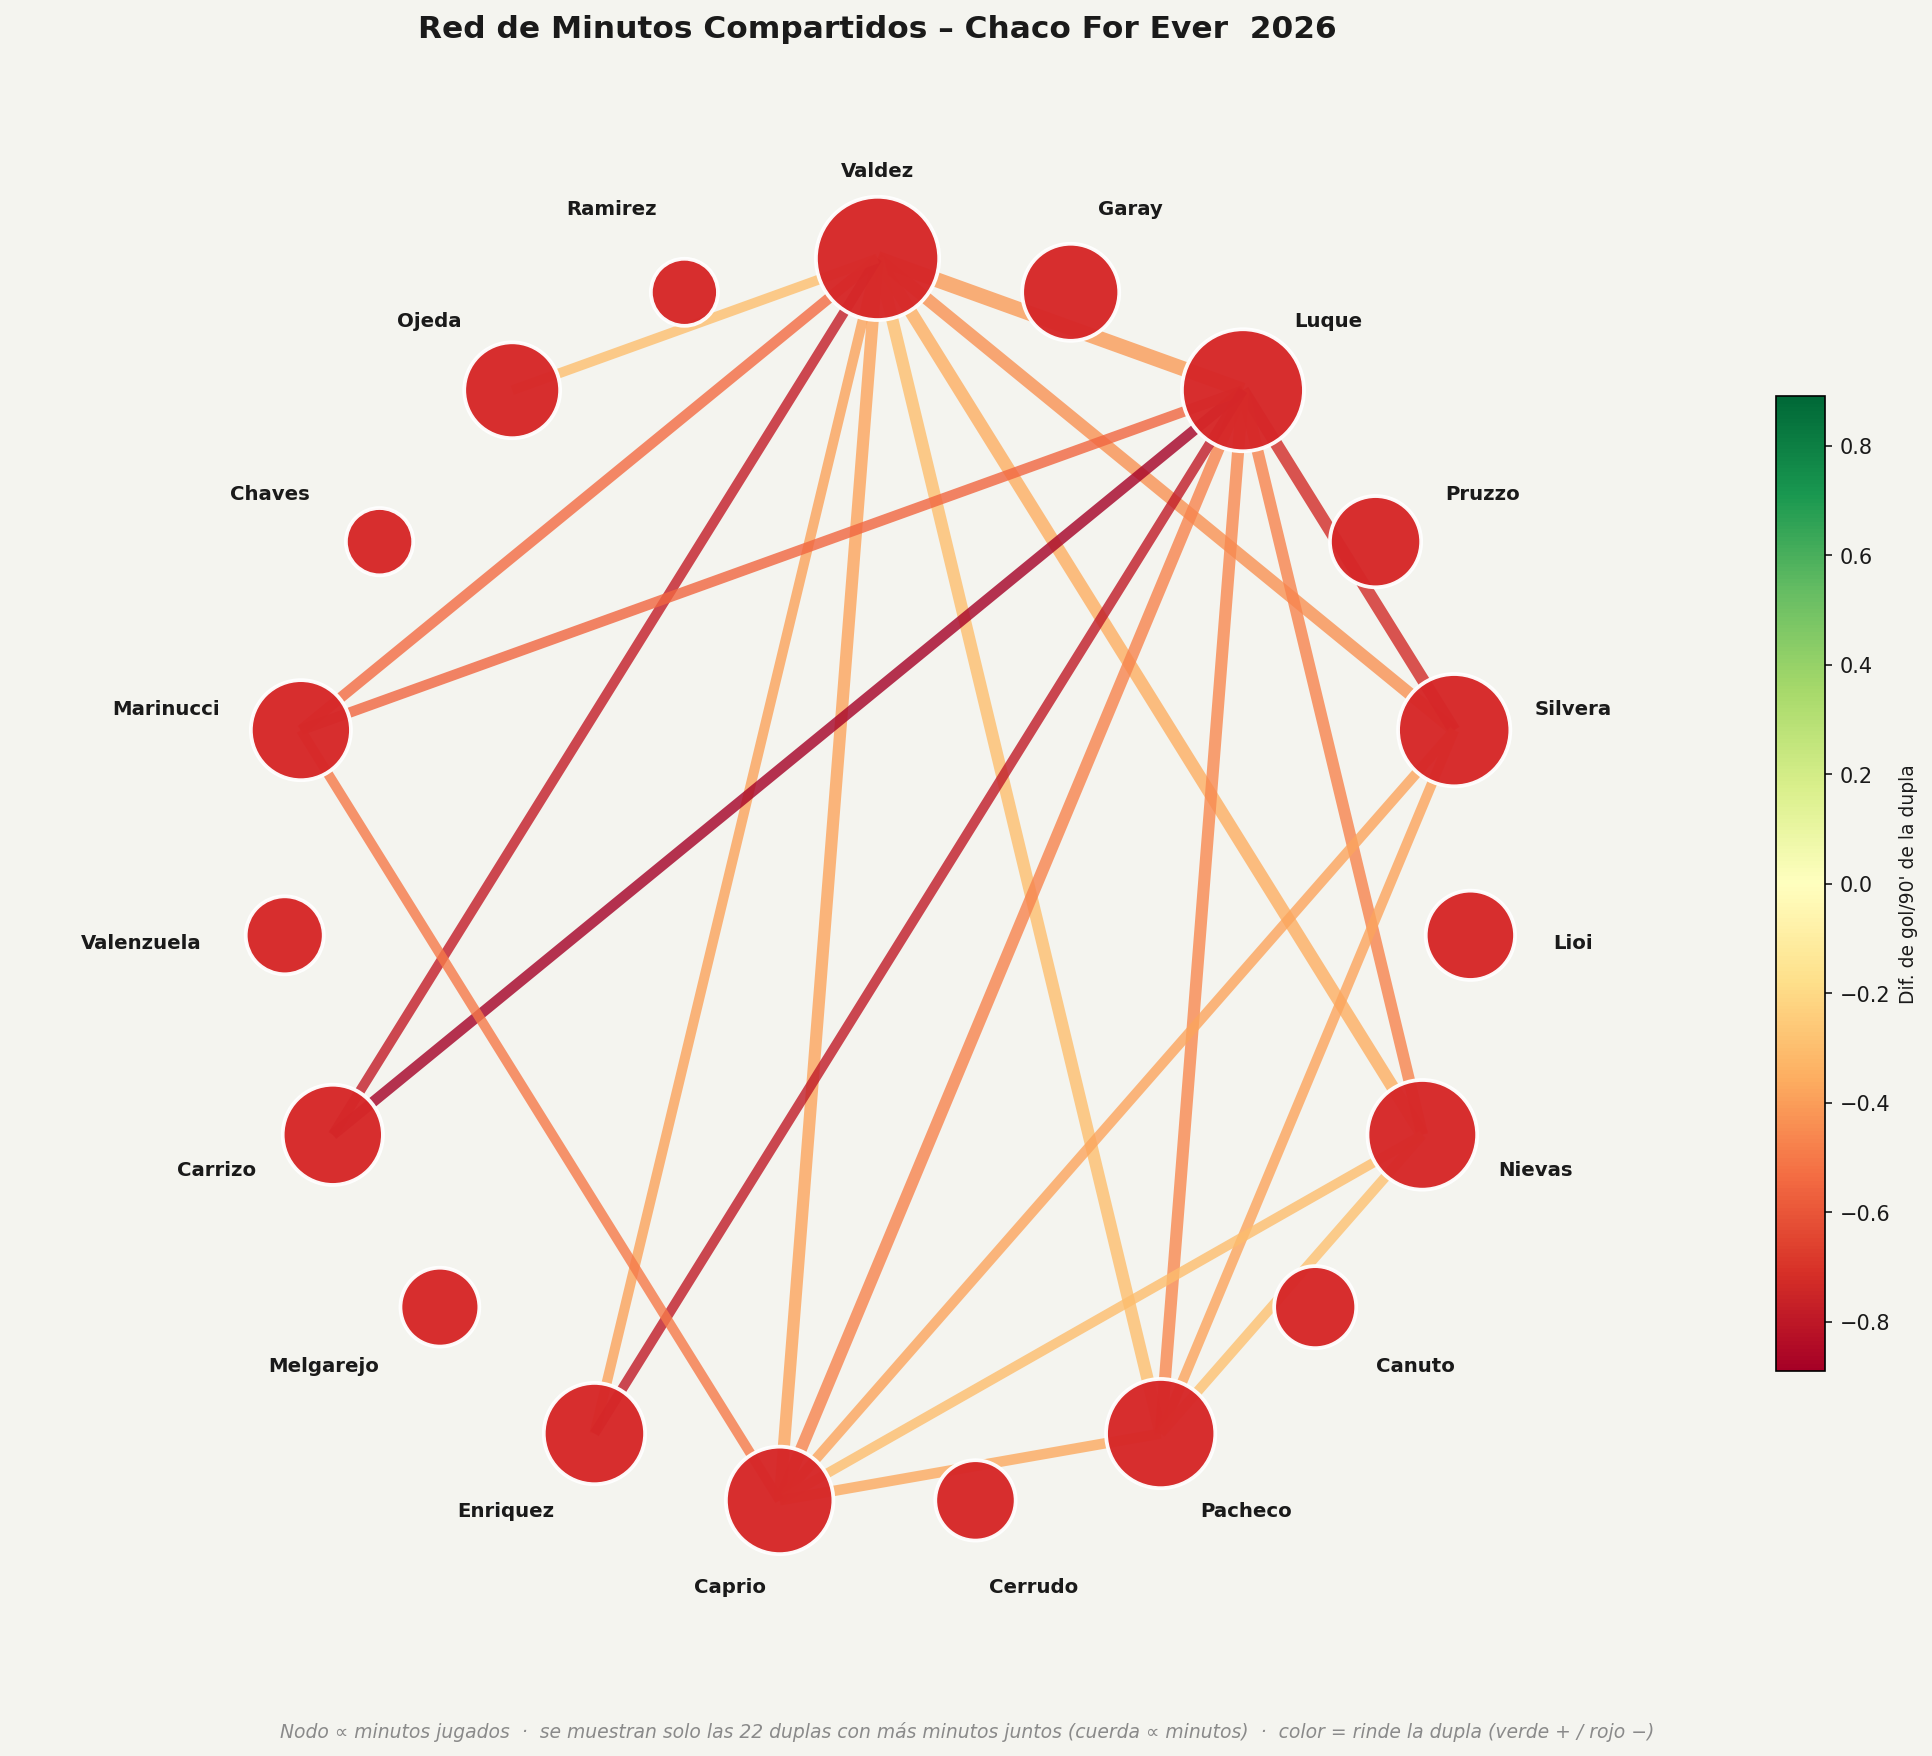

✅ red_minutos_compartidos.png  (19 jugadores, 170 duplas)


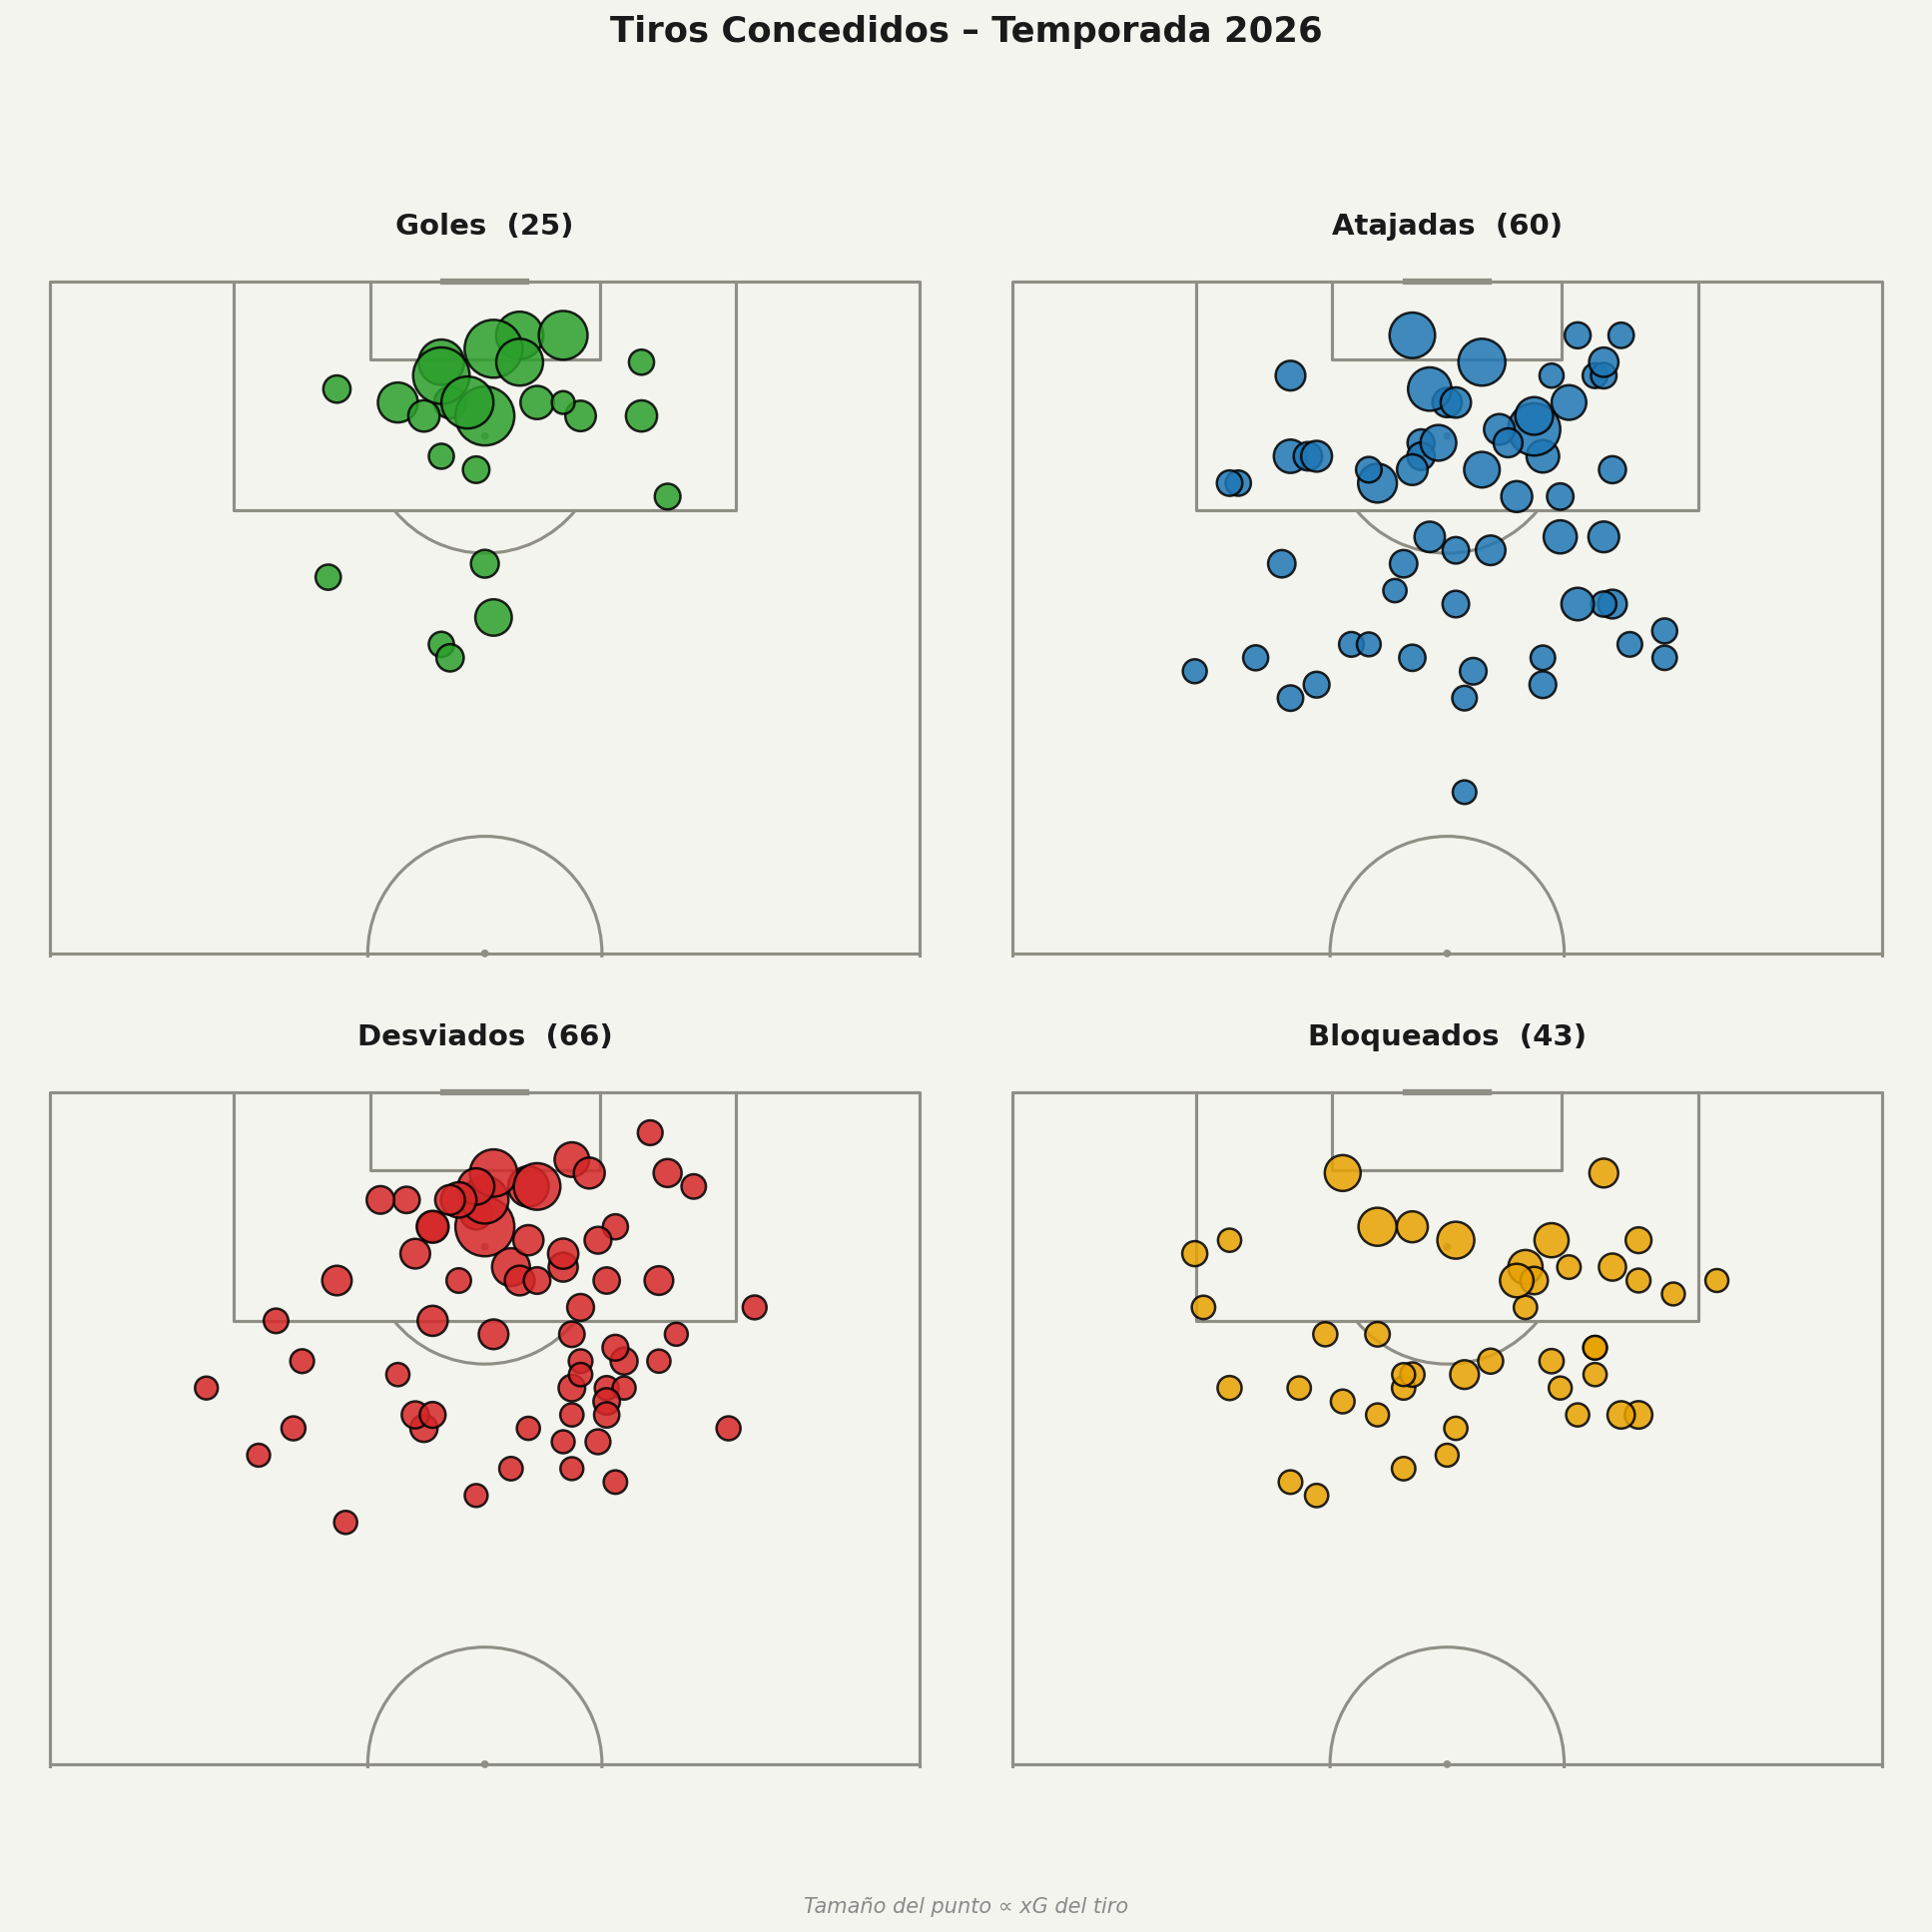

✅ tiros_concedidos_temporada.png


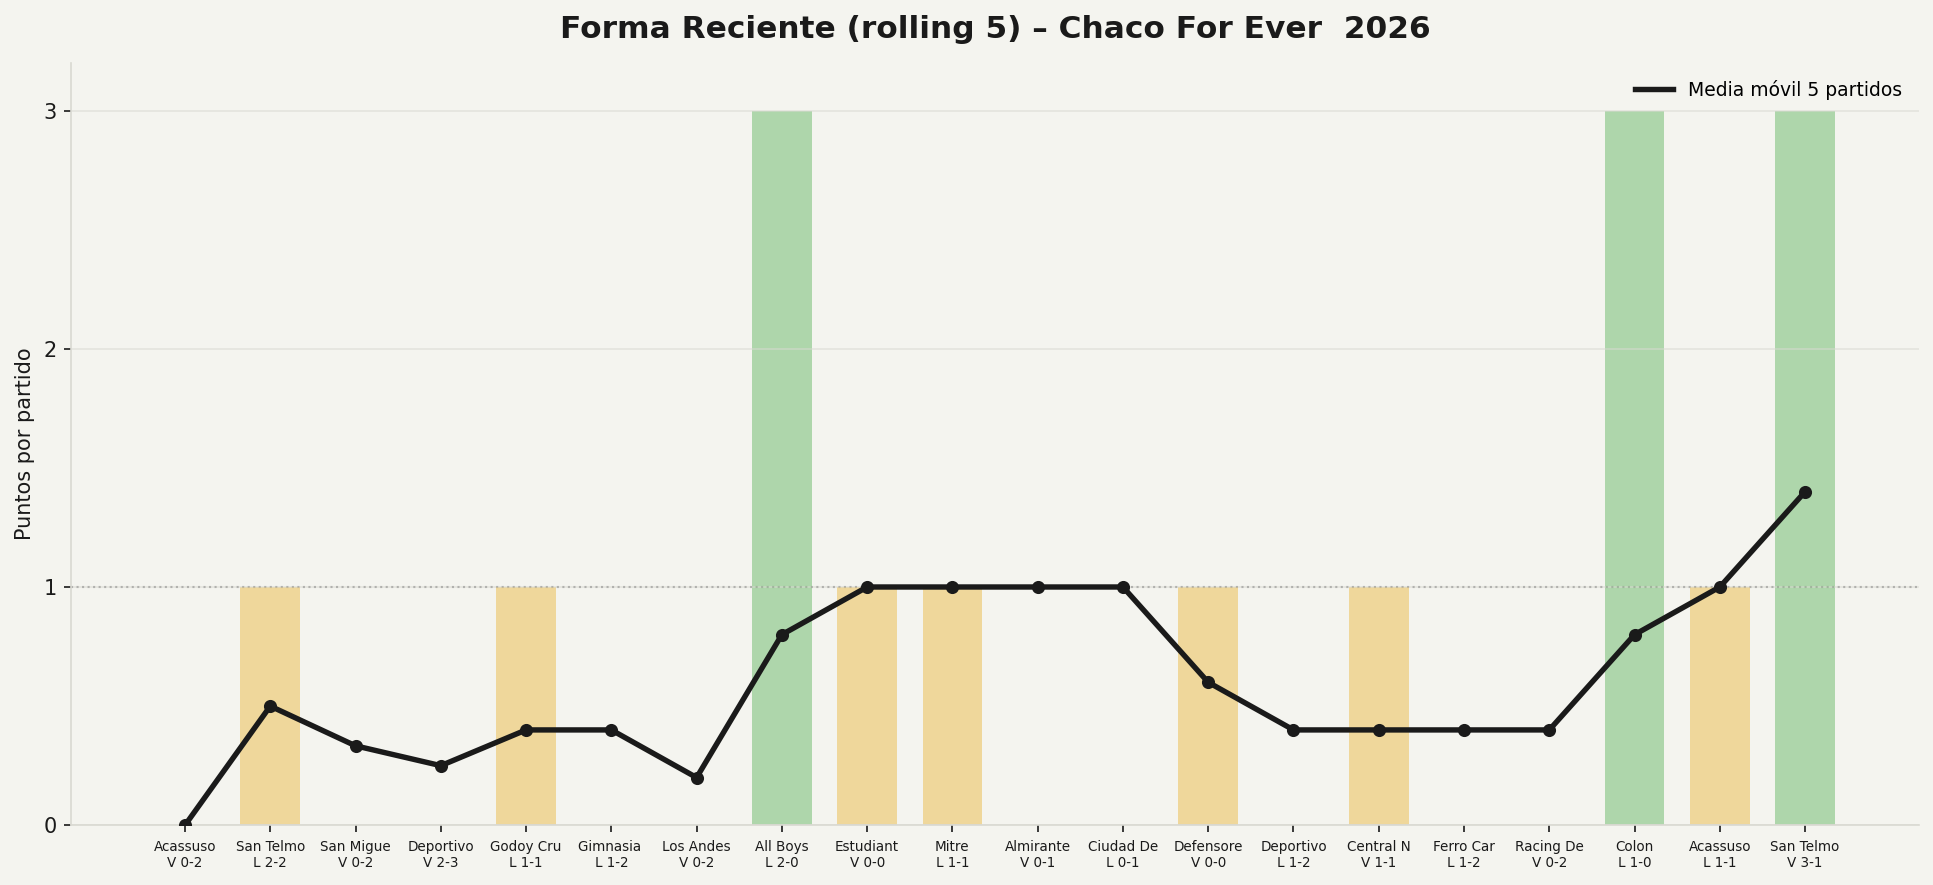

✅ forma_reciente.png


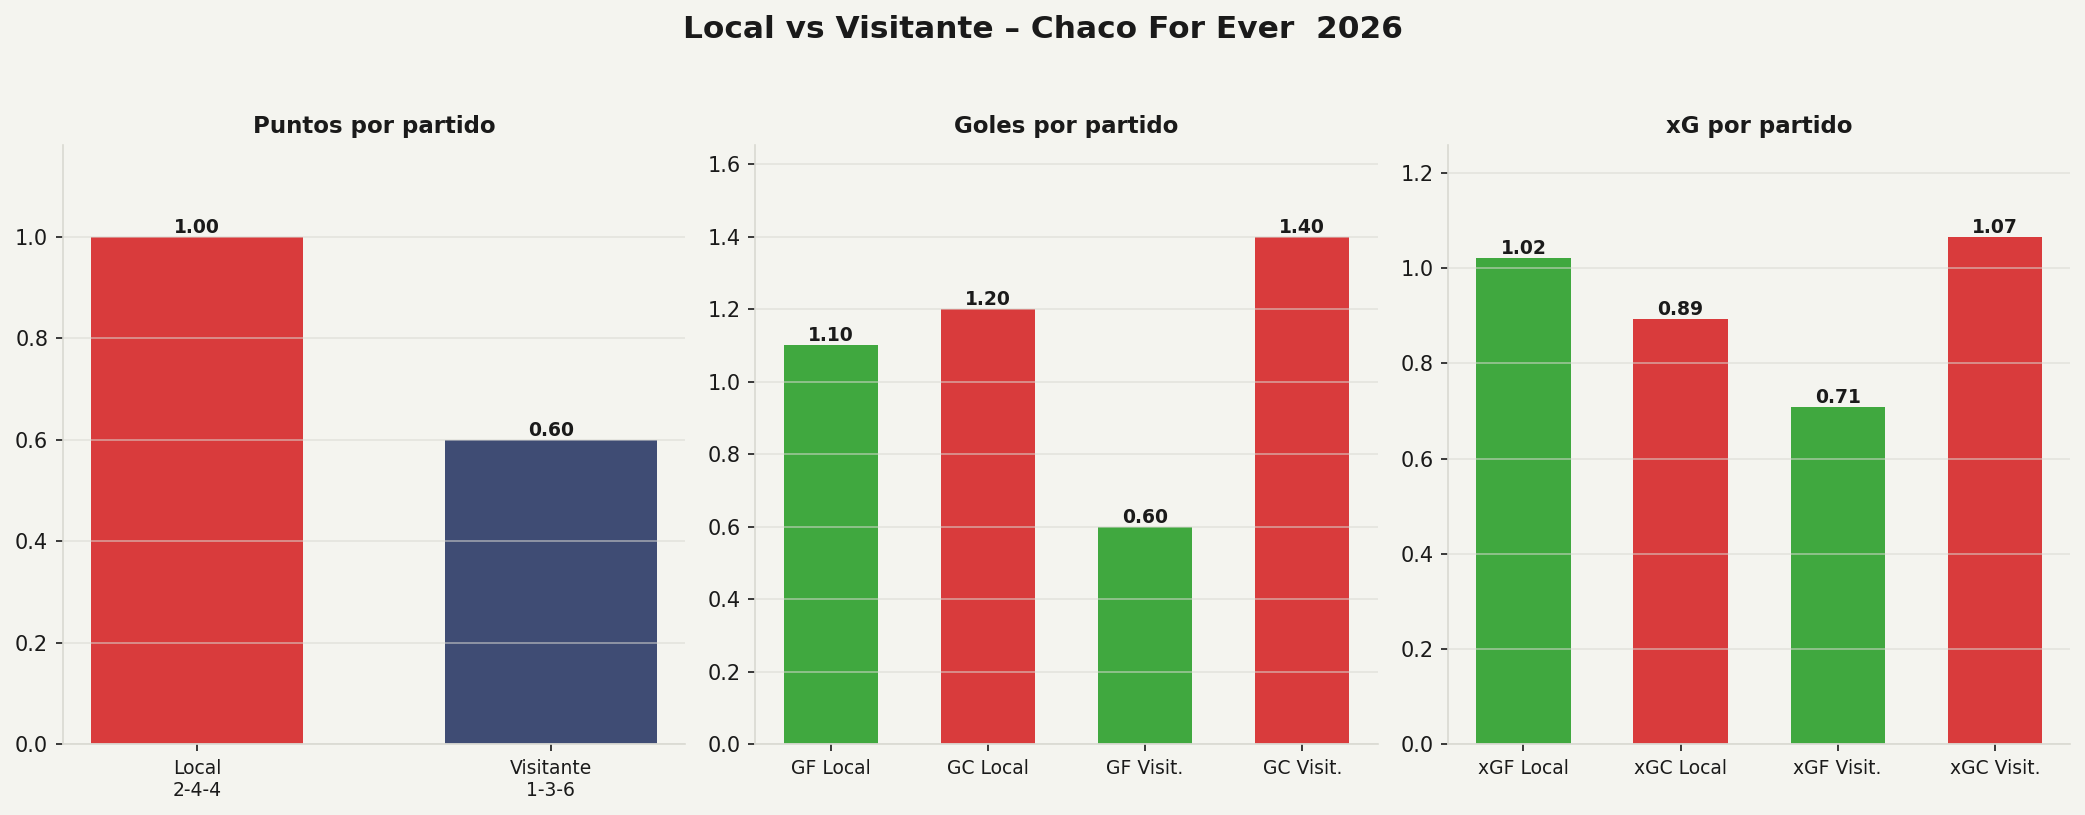

✅ local_vs_visitante.png


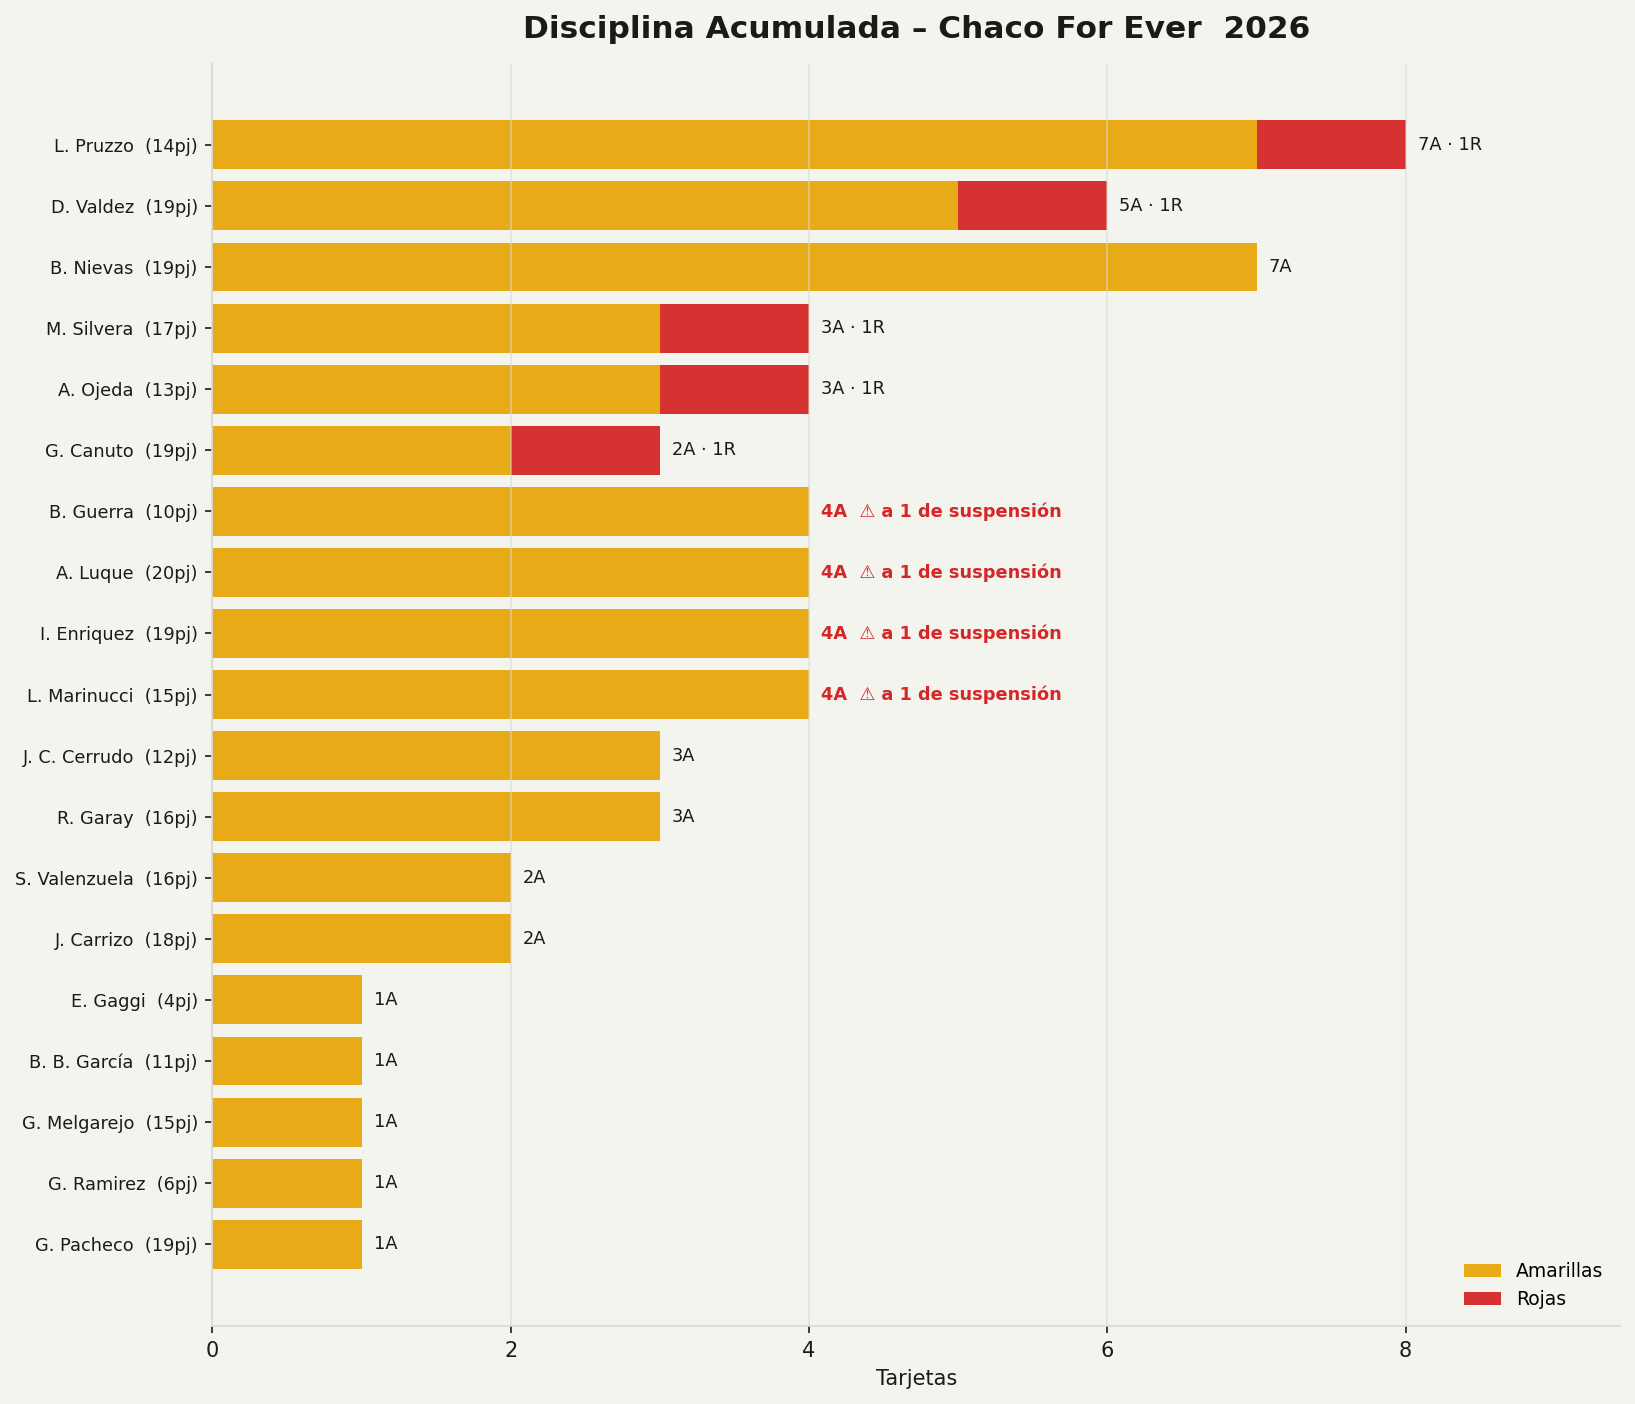

✅ disciplina.png


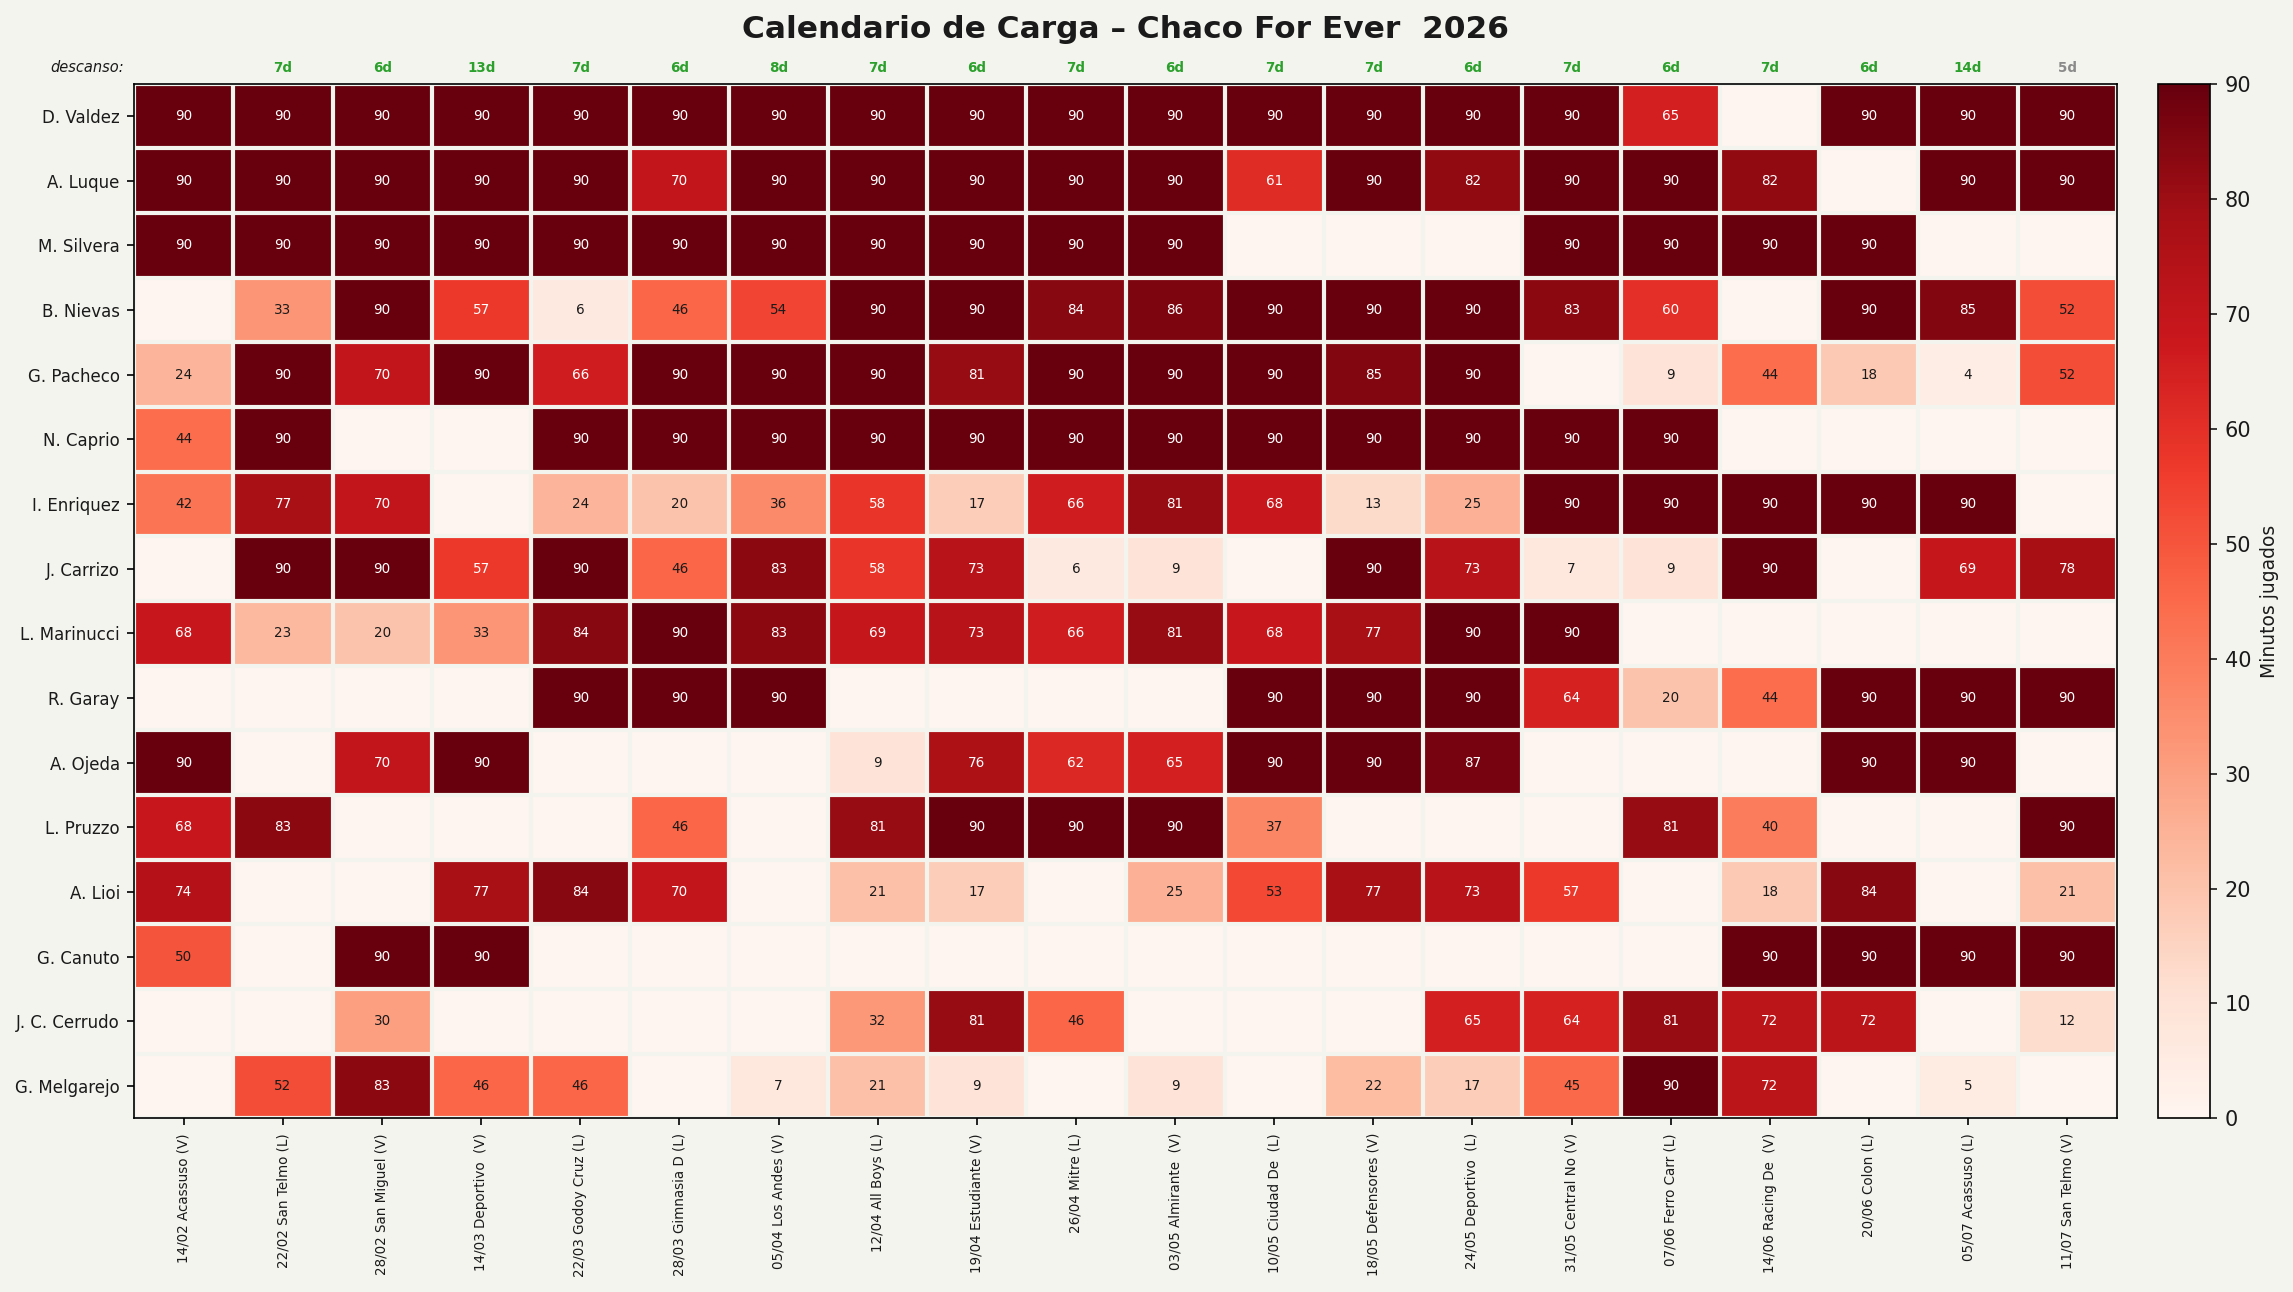

✅ calendario_carga.png


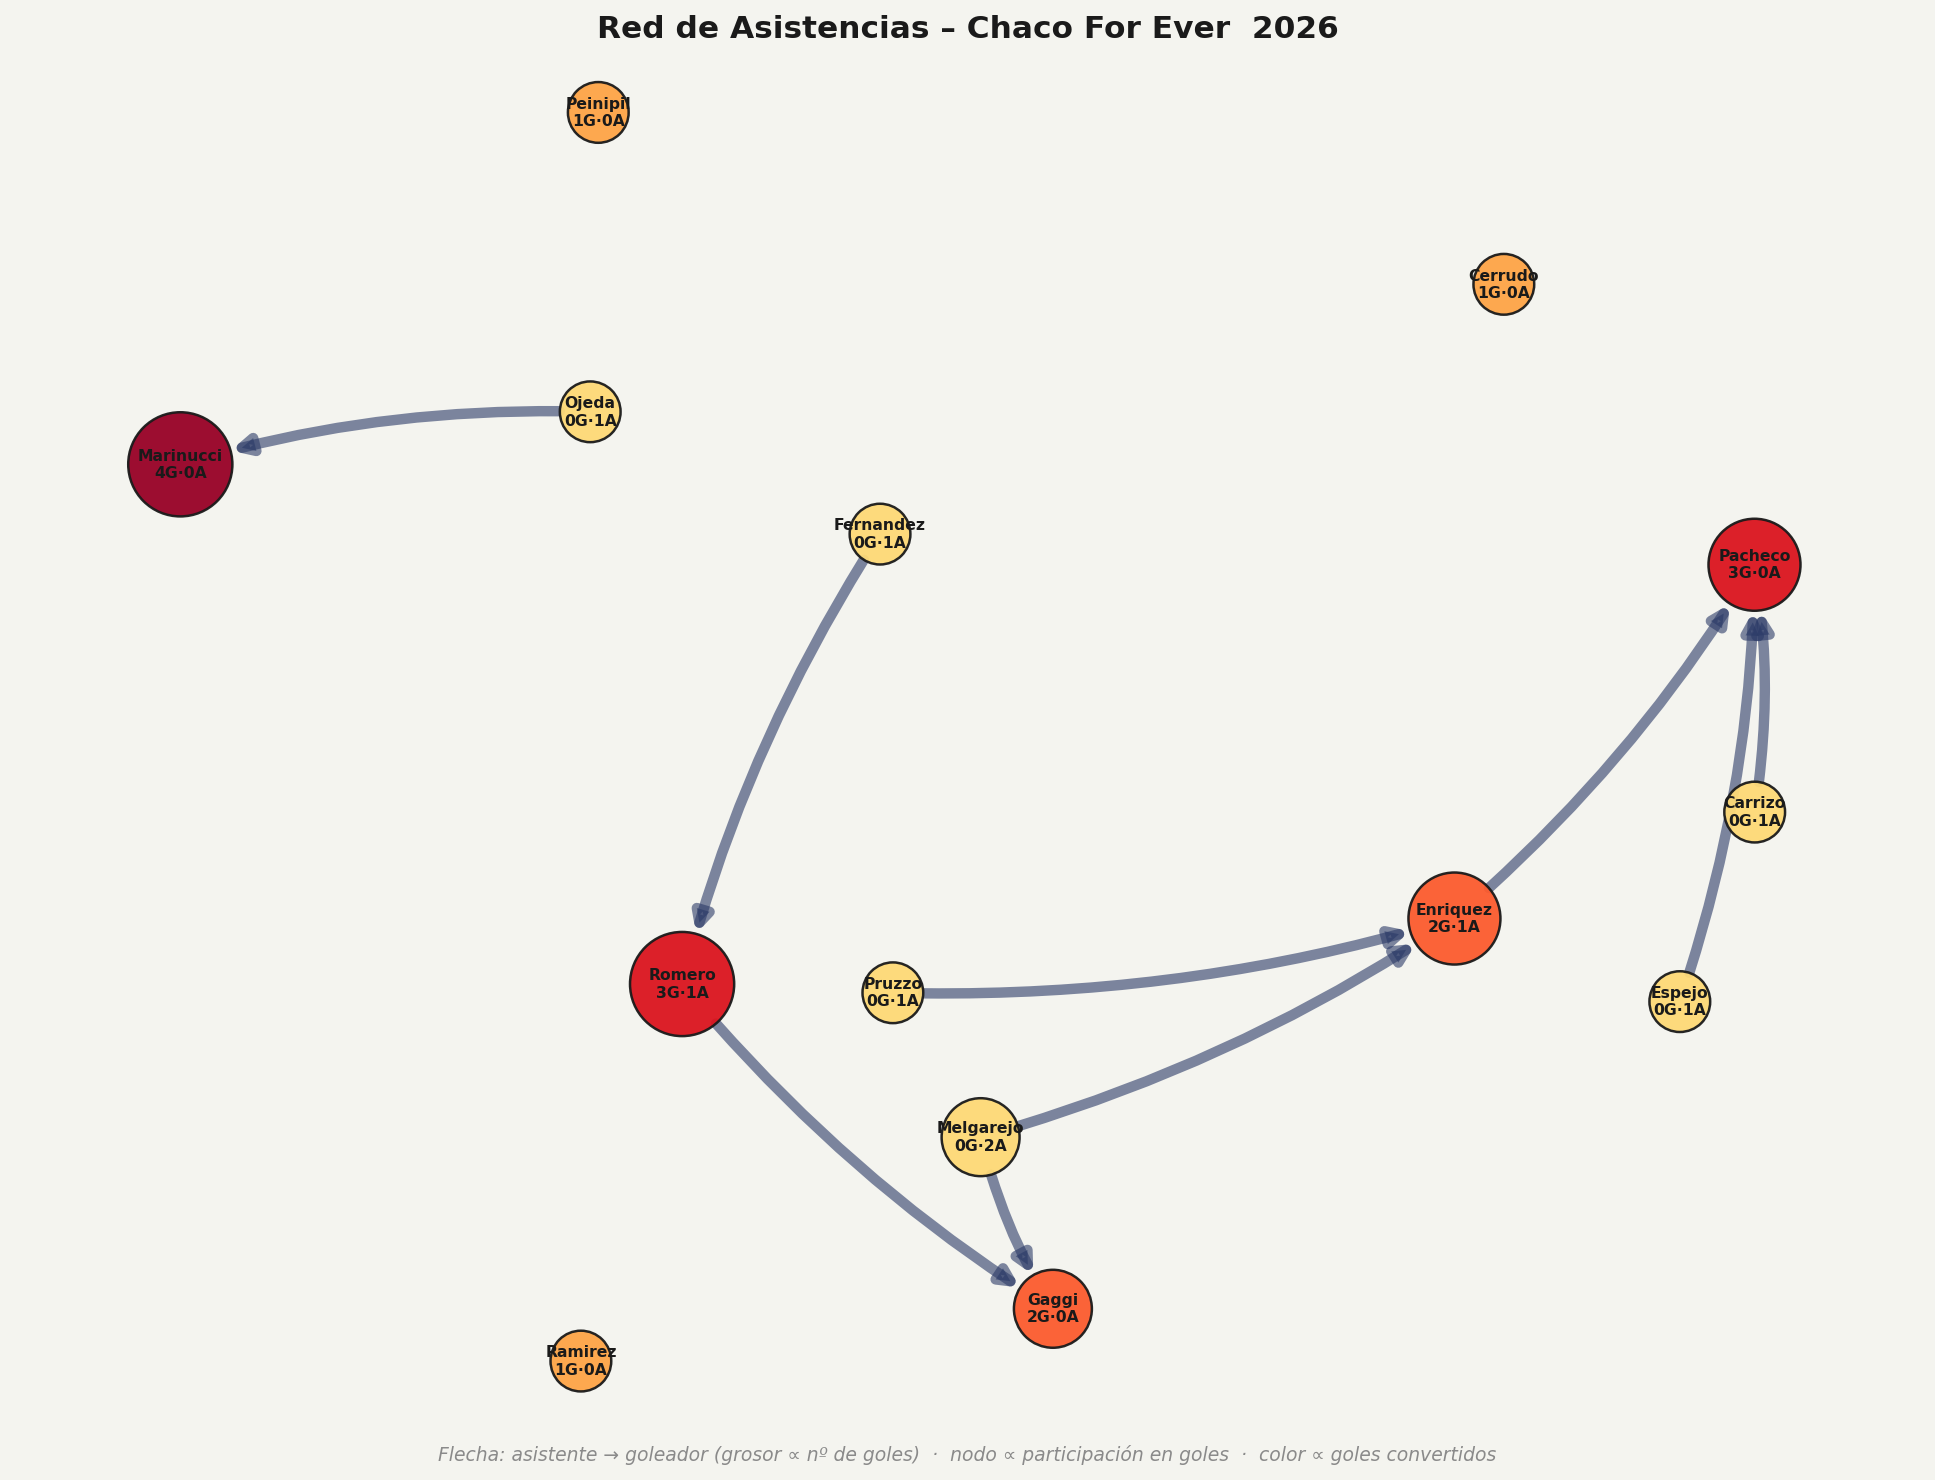

✅ red_asistencias.png  (14 jugadores, 9 conexiones)


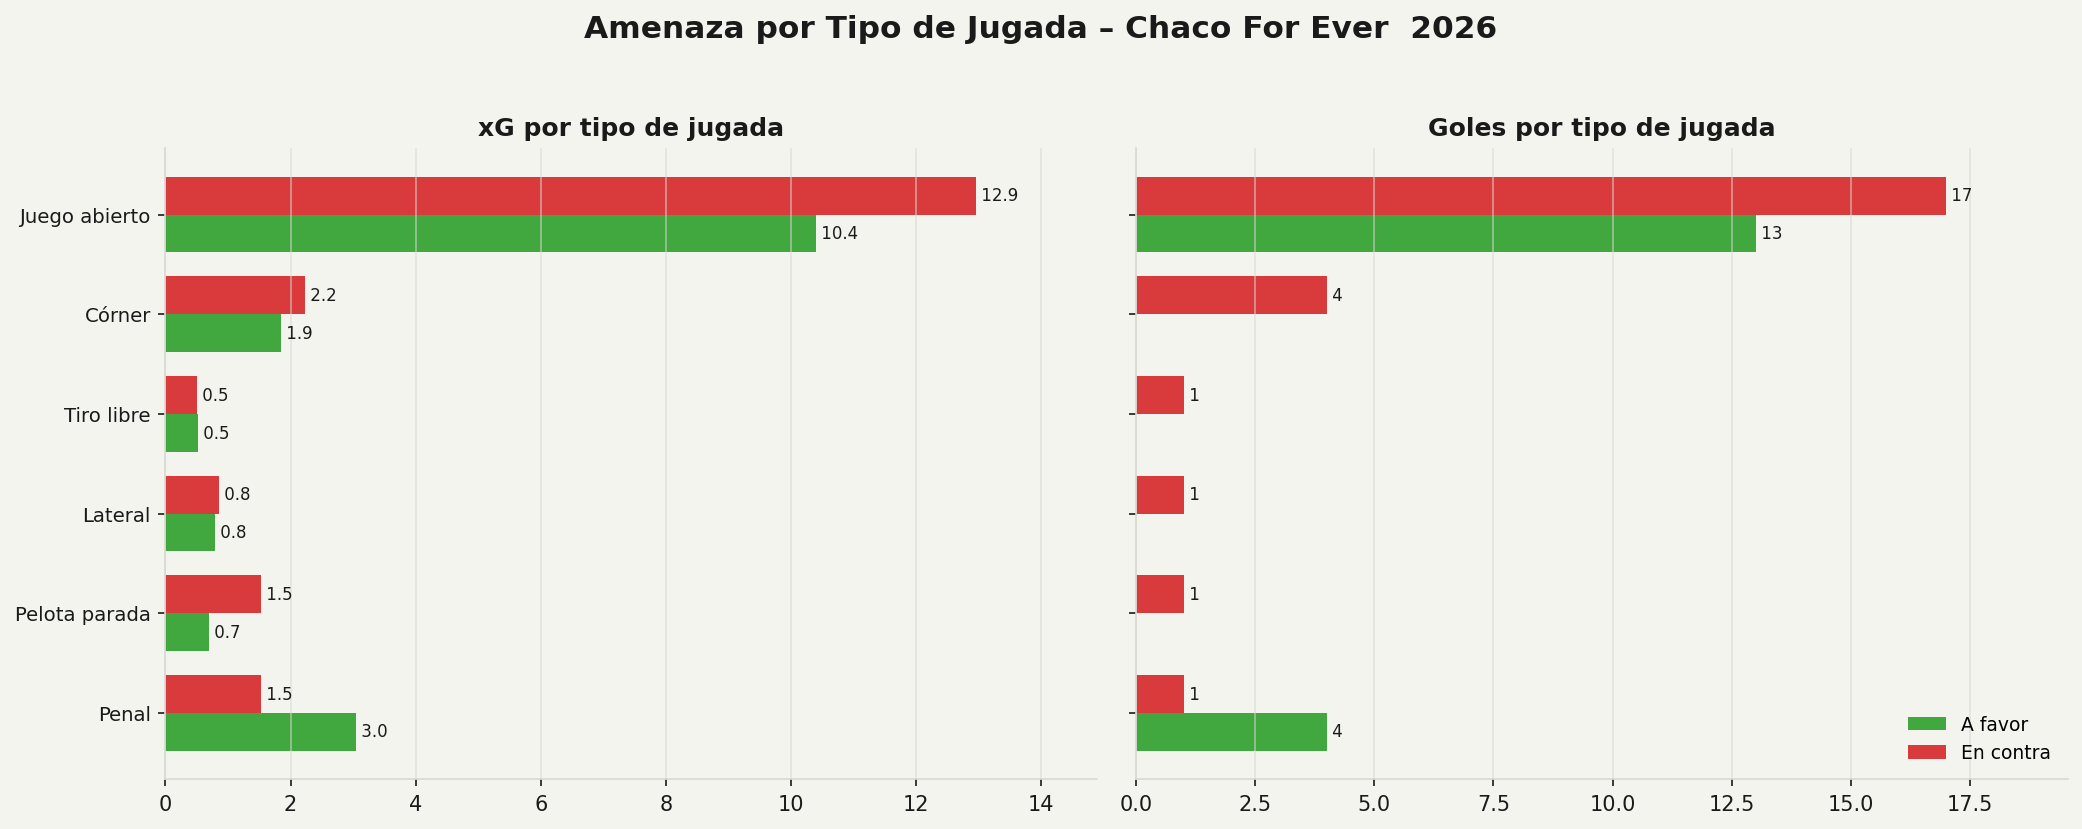

✅ amenaza_por_jugada.png


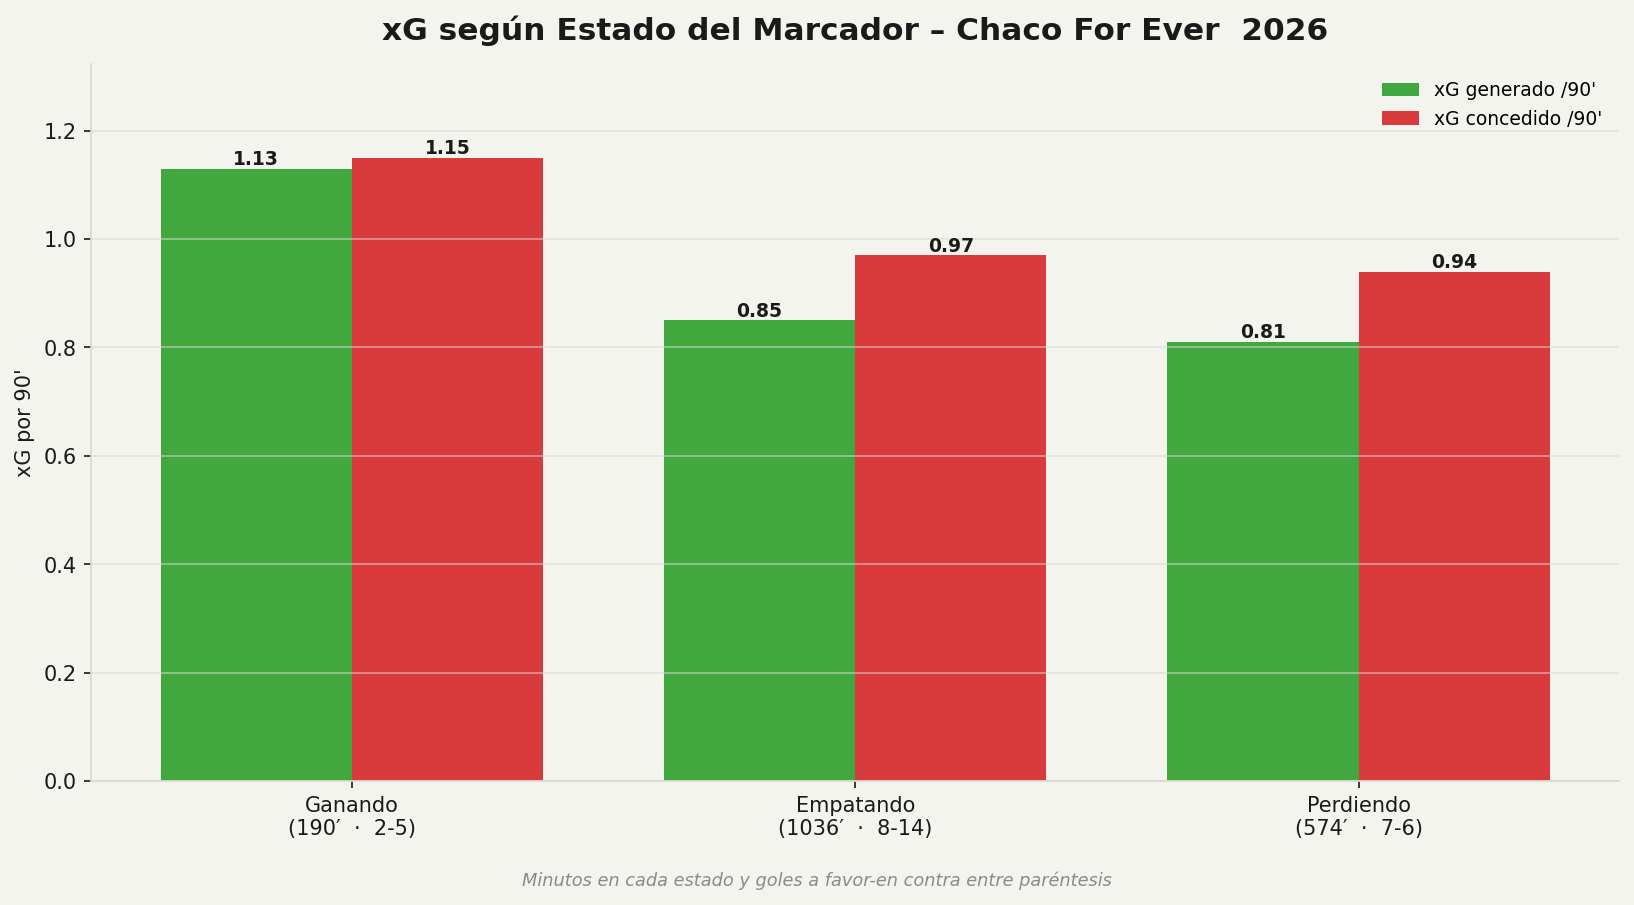

✅ xg_por_estado_marcador.png


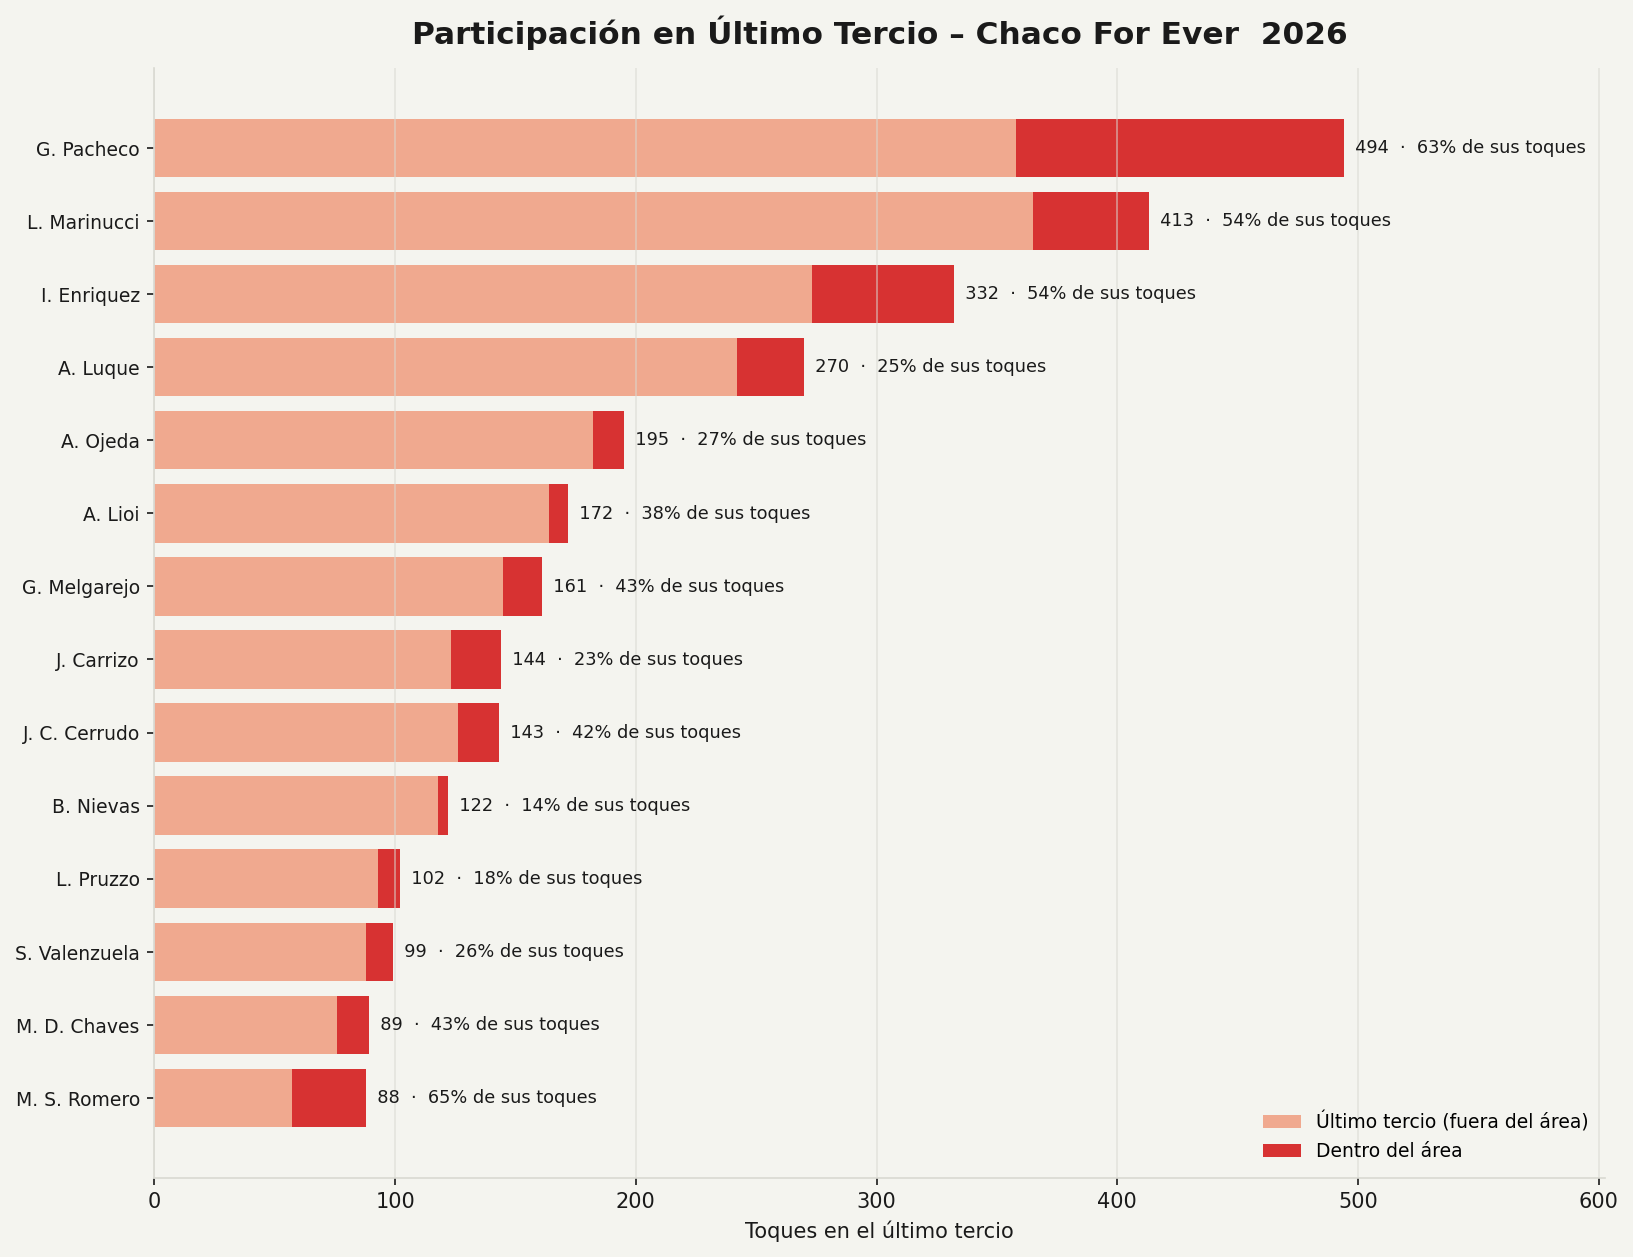

✅ toques_ultimo_tercio.png


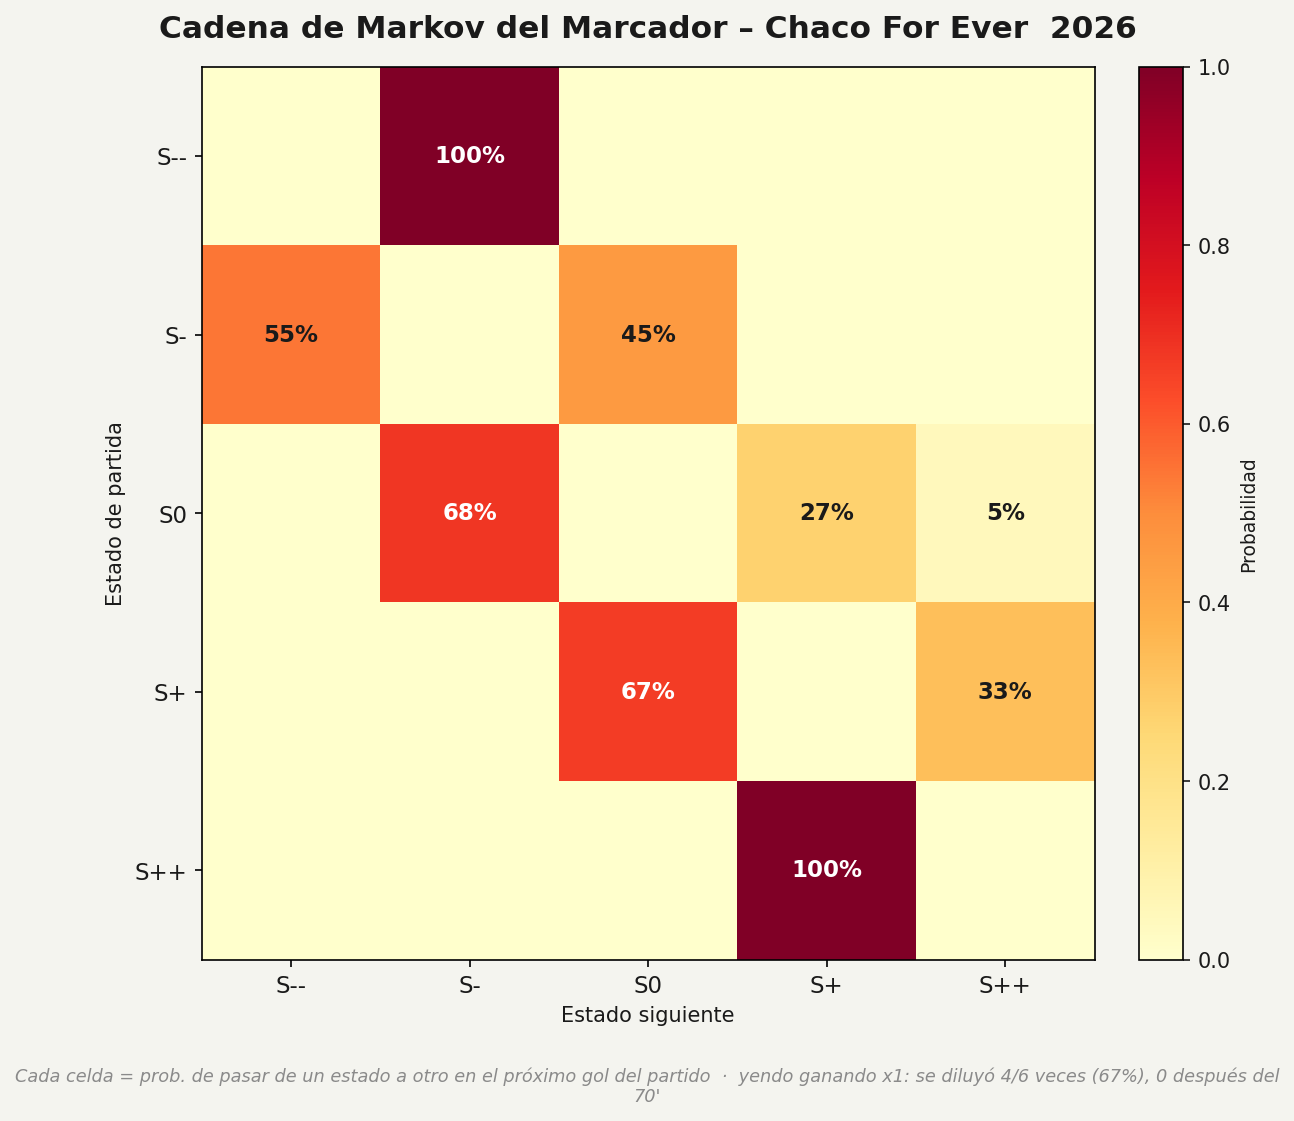

✅ markov_marcador.png


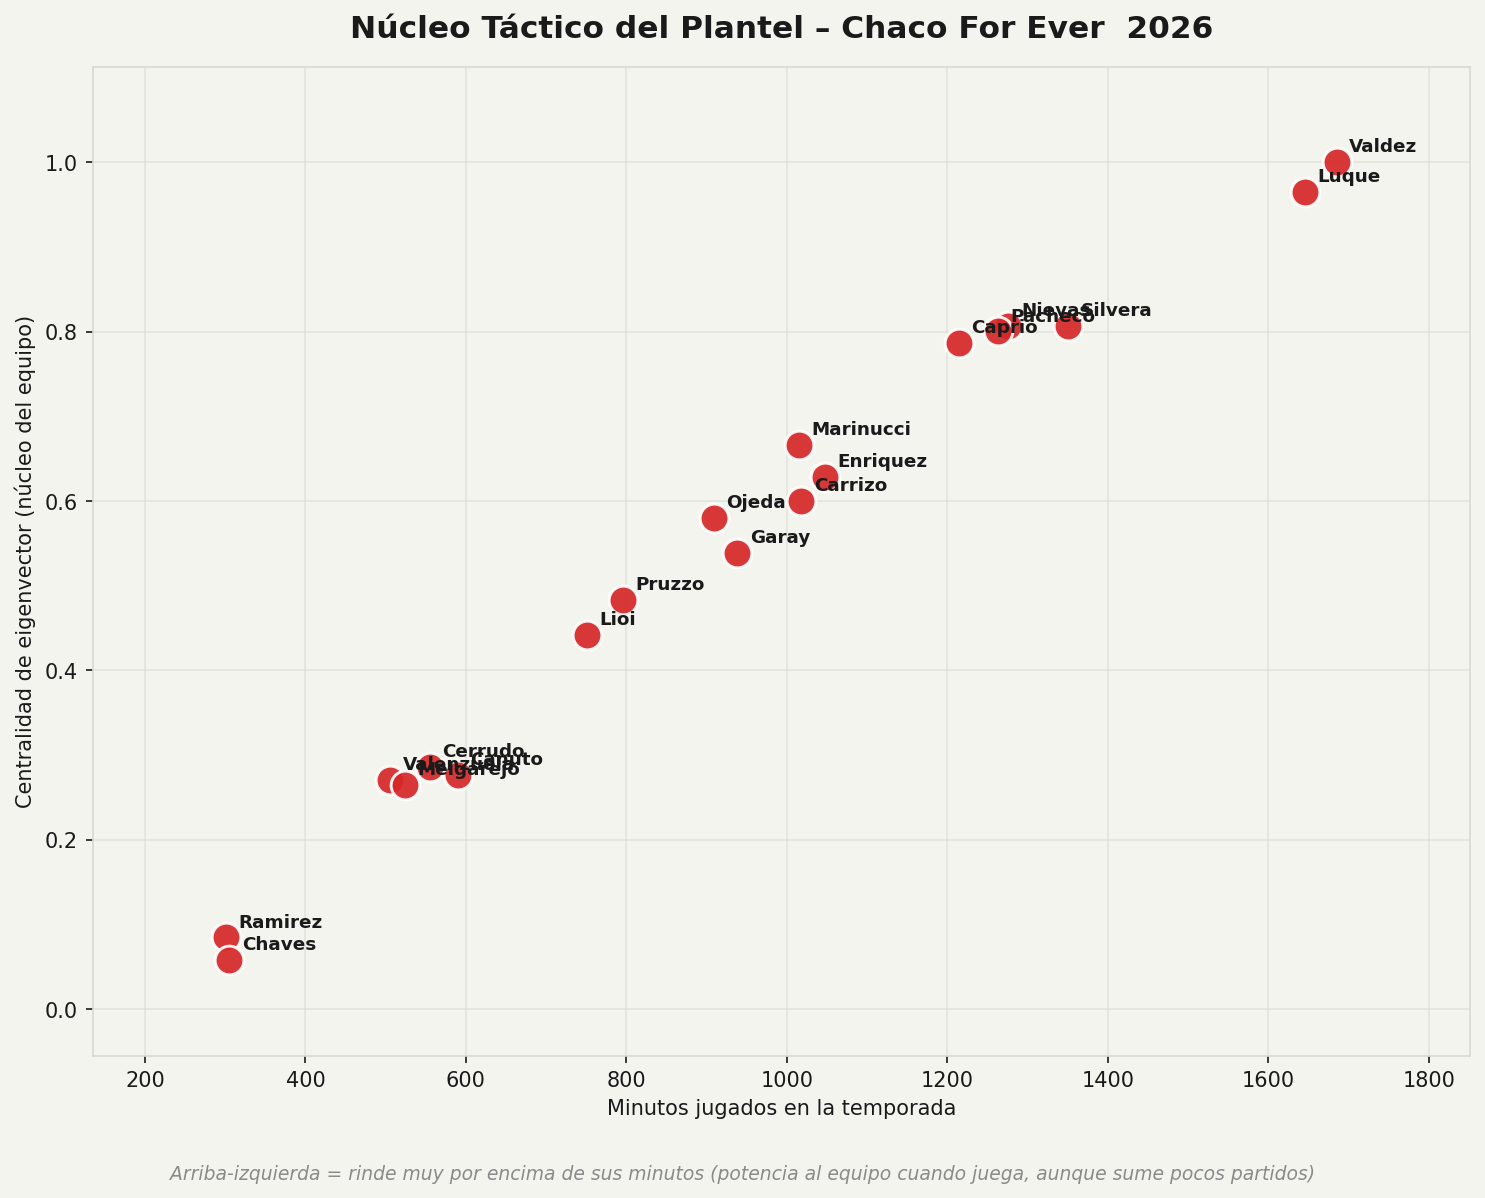

✅ nucleo_tactico.png


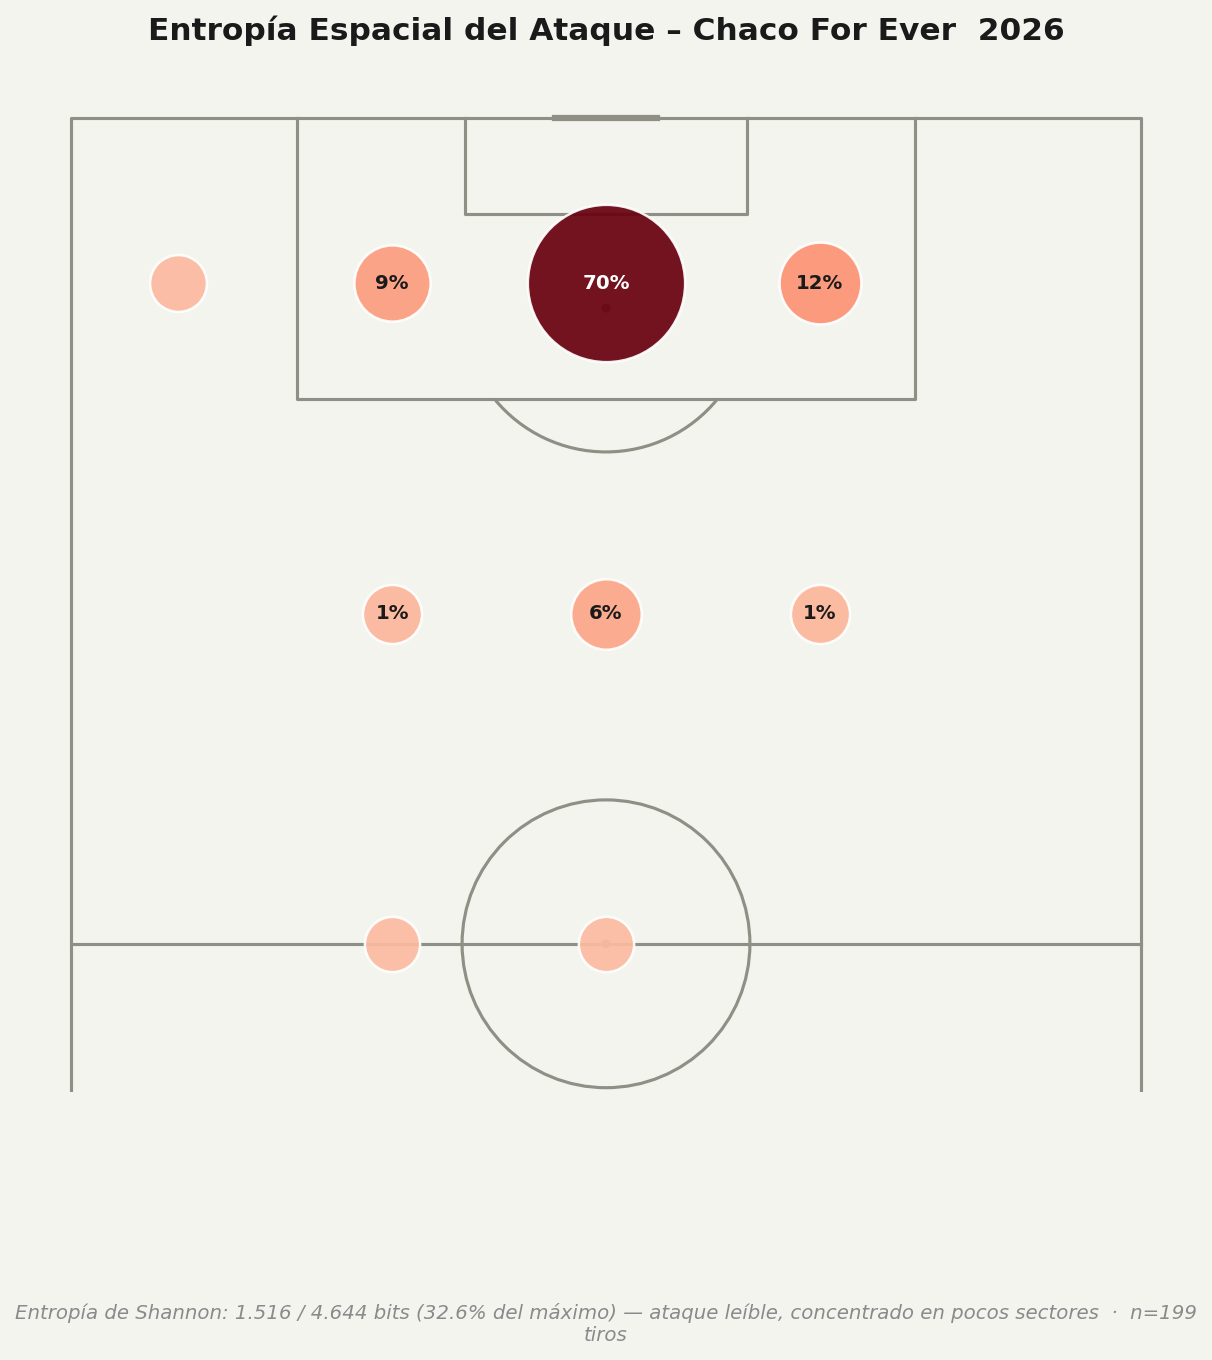

✅ entropia_tiros.png  (H=1.516 / 4.644 bits, 32.6% del máximo)


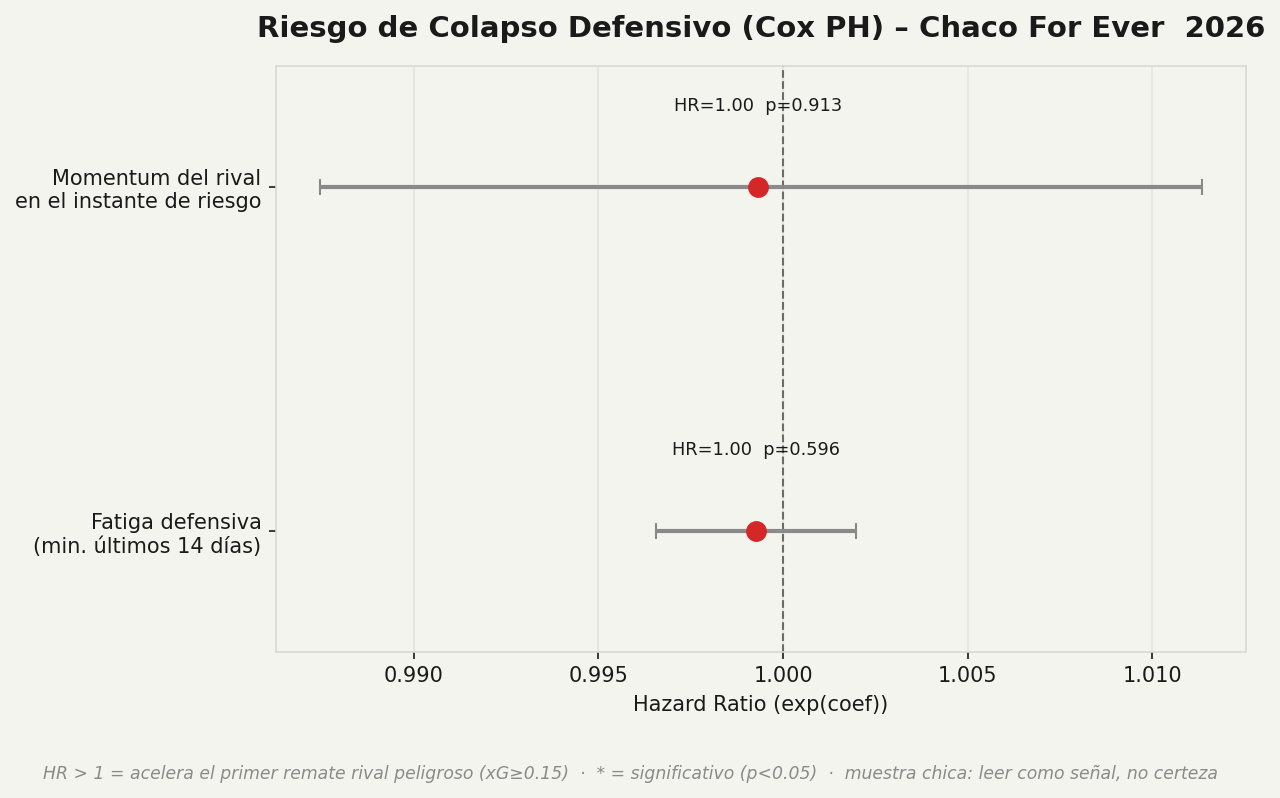

✅ riesgo_defensivo_cox.png
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%         p
covariate                                                                       
defensive_fatigue   0.999269             0.996569             1.001977  0.596336
momentum_at_risk    0.999331             0.987464             1.011342  0.912636


In [7]:
# ── Gráficos nuevos de temporada (doc IDEAS_NUEVAS, sección 2) ──
import pandas as pd

# 1) Red de minutos compartidos — diagrama de cuerdas circular: quién juega junto
#    y cómo le fue al equipo en esos minutos. Nodo ∝ minutos totales; solo se
#    dibujan las duplas con más minutos juntos (cuerda ∝ minutos), color = dif.
#    de gol/90' del equipo con esa dupla (verde = rinde, rojo = no).
nodes, edges = shared_minutes_network(match_keys_with_data, BASE_DIR, min_minutes=270)
if not nodes.empty:
    p = os.path.join(PLOTS_DIR, 'red_minutos_compartidos.png')
    plot_shared_minutes_network(nodes, edges, season=SEASON, min_edge_minutes=180,
                                top_edges=22, save_path=p)
    show(p)
    print(f'✅ red_minutos_compartidos.png  ({len(nodes)} jugadores, {len(edges)} duplas)')

# 2) Mapa de tiros CONCEDIDOS de la temporada — dónde nos generan peligro todo
#    el año (complemento defensivo del shotmap ofensivo de arriba).
conc = []
for mk in match_keys_with_data:
    sp = os.path.join(BASE_DIR, mk, 'shotmap_clean.csv')
    if os.path.exists(sp):
        df_s = pd.read_csv(sp)
        conc.append(df_s[df_s['isHome'] != is_home_match(mk)])
if conc:
    df_conc = pd.concat(conc, ignore_index=True)
    p = os.path.join(PLOTS_DIR, 'tiros_concedidos_temporada.png')
    plot_shotmap_4grid(df_conc, team_label='Tiros Concedidos',
                       title=f'Tiros Concedidos – Temporada {SEASON}', save_path=p)
    show(p)
    print('✅ tiros_concedidos_temporada.png')

# 3) Forma reciente (media móvil de 5 partidos) — muestra rachas, a diferencia
#    del acumulado de puntos de toda la temporada.
p = os.path.join(PLOTS_DIR, 'forma_reciente.png')
plot_recent_form(season_df, window=5, season=SEASON, save_path=p)
show(p)
print('✅ forma_reciente.png')

# 4) Local vs Visitante — puntos, goles y xG por partido según condición.
p = os.path.join(PLOTS_DIR, 'local_vs_visitante.png')
plot_home_away_panel(season_df, season=SEASON, save_path=p)
show(p)
print('✅ local_vs_visitante.png')

# 5) Disciplina acumulada — amarillas/rojas por jugador; marca a los que están
#    a una amarilla de la suspensión por acumulación.
p = os.path.join(PLOTS_DIR, 'disciplina.png')
plot_discipline(player_df, season=SEASON, suspension_at=5, save_path=p)
show(p)
print('✅ disciplina.png')

# 6) Calendario de carga — minutos por jugador a lo largo del año + días de
#    descanso entre fechas (para decidir rotaciones).
mat, meta = load_calendar(match_keys_with_data, BASE_DIR, top_n=16)
p = os.path.join(PLOTS_DIR, 'calendario_carga.png')
plot_load_calendar(mat, meta, season=SEASON, save_path=p)
show(p)
print('✅ calendario_carga.png')

# 7) Red de asistencias — quién habilita a quién en los goles (asistente →
#    goleador). Complementa la red de minutos con la conexión ofensiva real.
an, ae = assists_network(match_keys_with_data, BASE_DIR)
if not an.empty:
    p = os.path.join(PLOTS_DIR, 'red_asistencias.png')
    plot_assists_network(an, ae, season=SEASON, save_path=p)
    show(p)
    print(f'✅ red_asistencias.png  ({len(an)} jugadores, {len(ae)} conexiones)')

# 8) Amenaza por tipo de jugada — goles/xG a favor y en contra según situation
#    (juego abierto vs pelota parada, córner...). Accionable para entrenar.
threat = threat_by_situation(match_keys_with_data, BASE_DIR)
if not threat.empty:
    p = os.path.join(PLOTS_DIR, 'amenaza_por_jugada.png')
    plot_threat_by_situation(threat, season=SEASON, save_path=p)
    show(p)
    print('✅ amenaza_por_jugada.png')

# 9) xG según estado del marcador — ¿generás cuando vas ganando o te replegás
#    de más? Patrón de gestión de ventaja.
xgst = xg_by_score_state(match_keys_with_data, BASE_DIR)
if not xgst.empty:
    p = os.path.join(PLOTS_DIR, 'xg_por_estado_marcador.png')
    plot_xg_by_score_state(xgst, season=SEASON, save_path=p)
    show(p)
    print('✅ xg_por_estado_marcador.png')

# 10) Toques en último tercio / área rival por jugador — participación ofensiva
#     real sin necesitar datos de pases (sale de heatmaps).
ft = final_third_touches(match_keys_with_data, BASE_DIR, top_n=14)
if not ft.empty:
    p = os.path.join(PLOTS_DIR, 'toques_ultimo_tercio.png')
    plot_final_third_touches(ft, season=SEASON, save_path=p)
    show(p)
    print('✅ toques_ultimo_tercio.png')

# 11) Cadena de Markov del estado del marcador — matriz de transición S--/S-/S0/
#     S+/S++ (perspectiva Chaco). Mide la "madurez" para gestionar el resultado:
#     ¿qué tan seguido se diluye una ventaja de 1 gol, y en qué minuto?
markov_matrix, markov_trans = markov_game_state(match_keys_with_data, BASE_DIR)
p = os.path.join(PLOTS_DIR, 'markov_marcador.png')
plot_markov_transitions(markov_matrix, markov_trans, season=SEASON, save_path=p)
show(p)
print('✅ markov_marcador.png')

# 12) Núcleo táctico (centralidad de eigenvector) — sobre el mismo grafo de
#     minutos compartidos, pondera cada arista por el rendimiento neto de la
#     dupla (no solo minutos). Detecta "inamovibles" que potencian al equipo
#     aunque no tengan estadísticas individuales vistosas.
eigen_nodes = eigenvector_centrality_network(nodes, edges, min_minutes=270)
p = os.path.join(PLOTS_DIR, 'nucleo_tactico.png')
plot_eigen_centrality(eigen_nodes, season=SEASON, save_path=p)
show(p)
print('✅ nucleo_tactico.png')

# 13) Entropía de Shannon del shotmap propio — ¿el ataque es impredecible o el
#     rival ya sabe de dónde va a llegar el peligro? coord_x del shotmap mide
#     distancia AL ARCO (0=línea de gol), así que se usa toda la zona de tiro.
entropy_stats = shot_entropy(match_keys_with_data, BASE_DIR)
if entropy_stats['n_shots']:
    p = os.path.join(PLOTS_DIR, 'entropia_tiros.png')
    plot_shot_entropy(entropy_stats, season=SEASON, save_path=p)
    show(p)
    print(f"✅ entropia_tiros.png  (H={entropy_stats['entropy']} / "
         f"{entropy_stats['max_entropy']} bits, {entropy_stats['pct_of_max']}% del máximo)")

# 14) Riesgo de colapso defensivo (Cox Proportional Hazards) — ¿la fatiga
#     acumulada por la línea defensiva (min. últimos 14 días) y el momentum
#     rival aceleran el primer remate peligroso (xG≥0.15) que recibimos?
#     Muestra chica (34 partidos): leer como señal direccional, no certeza.
surv = build_defensive_survival_dataset(match_keys_with_data, BASE_DIR)
if surv['event'].sum() >= 2 and surv['defensive_fatigue'].std() > 0:
    cph = fit_defensive_hazard_model(surv)
    p = os.path.join(PLOTS_DIR, 'riesgo_defensivo_cox.png')
    plot_defensive_hazard(cph, season=SEASON, save_path=p)
    show(p)
    print('✅ riesgo_defensivo_cox.png')
    print(cph.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
         .to_string())
else:
    print('⚠️  Cox omitido: pocos eventos de riesgo o sin variación en la fatiga.')

## 5. Análisis de cambios en la temporada

In [8]:
subs_df = substitution_analysis(match_keys_with_data, BASE_DIR)
if not subs_df.empty:
    print(f'Total cambios de Chaco: {len(subs_df)}')
    avg_min = subs_df['minute'].mean()
    print(f'Minuto promedio de primer cambio: {avg_min:.1f}\'')
    print('\nJugadores más introducidos como suplentes:')
    print(subs_df['player_in'].value_counts().head(10).to_string())

Total cambios de Chaco: 96
Minuto promedio de primer cambio: 68.2'

Jugadores más introducidos como suplentes:
player_in
G. Melgarejo     9
A. Alonso        8
L. Espejo        8
I. Enriquez      7
B. Guerra        7
A. Lioi          6
S. Valenzuela    5
M. D. Chaves     5
G. Pacheco       5
J. Carrizo       4


## 6. Perfiles individuales — Pizza y Radar
Percentiles por-90 de cada jugador de Chaco contra el **pool** de todos los
jugadores que aparecen en los partidos scrapeados (Chaco + rivales = referencia
de la Primera Nacional). Genera un pizza por jugador y radares comparativos.

In [9]:
# Pool de jugadores (Chaco + rivales) con métricas por-90
POOL_MIN_MINUTES = 90      # mínimo de minutos para entrar al pool
PIZZA_MIN_MINUTES = 450    # mínimo para generarle pizza a un jugador de Chaco (5 PT)

pool = player_pool(match_keys_with_data, BASE_DIR, min_minutes=POOL_MIN_MINUTES)
print(f'Pool: {len(pool)} jugadores ({int(pool["is_chaco"].sum())} de Chaco)')

# Un pizza por cada jugador de Chaco con suficientes minutos
PIZZA_DIR = os.path.join(PLOTS_DIR, 'jugadores')
os.makedirs(PIZZA_DIR, exist_ok=True)

chaco_pool = pool[(pool['is_chaco']) & (pool['minutes'] >= PIZZA_MIN_MINUTES)]
chaco_pool = chaco_pool.sort_values('minutes', ascending=False)

for _, jugador in chaco_pool.iterrows():
    nombre = jugador['player_name']
    pcts = player_percentiles(nombre, pool)
    if pcts:
        fig = plot_player_pizza(nombre, pcts, context_label=f'Temporada {SEASON}')
        if fig:
            safe = nombre.replace(' ', '_').replace('.', '')
            save_fig(fig, os.path.join(PIZZA_DIR, f'pizza_{safe}.png'))

print(f'✅ {len(chaco_pool)} pizzas generadas en graficos/jugadores/')
print(chaco_pool[['player_name','matches','minutes']].to_string(index=False))

Pool: 155 jugadores (29 de Chaco)
✅ 17 pizzas generadas en graficos/jugadores/
  player_name  matches  minutes
    D. Valdez       19   1685.0
     A. Luque       20   1645.0
   M. Silvera       17   1350.0
    B. Nievas       19   1276.0
   G. Pacheco       19   1263.0
    N. Caprio       20   1214.0
  I. Enriquez       19   1047.0
   J. Carrizo       18   1018.0
 L. Marinucci       15   1015.0
     R. Garay       16    938.0
     A. Ojeda       13    909.0
    L. Pruzzo       14    796.0
      A. Lioi       18    751.0
    G. Canuto       19    590.0
J. C. Cerrudo       12    555.0
 G. Melgarejo       15    524.0
S. Valenzuela       16    506.0


In [10]:
# Radar clásico: compara DOS jugadores en sus métricas por 90'.
# Conviene comparar jugadores de rol parecido — un arquero (position 'G') contra
# un delantero no dice nada, así que por defecto excluimos arqueros.
field_pool = chaco_pool[chaco_pool['position'] != 'G']

# Cambiá los nombres acá — deben existir en el pool (ver lista de arriba)
PLAYER_A = field_pool.iloc[0]['player_name'] if len(field_pool) > 0 else None
PLAYER_B = field_pool.iloc[1]['player_name'] if len(field_pool) > 1 else None

if PLAYER_A and PLAYER_B:
    print(f'Comparando: {PLAYER_A}  vs  {PLAYER_B}')
    comp = compare_players(PLAYER_A, PLAYER_B, pool)
    if comp:
        fig = plot_players_radar(comp)
        if fig:
            safe = f"radar_{PLAYER_A.replace(' ','_')}_vs_{PLAYER_B.replace(' ','_')}".replace('.','')
            save_fig(fig, os.path.join(PIZZA_DIR, f'{safe}.png'))
            print(f'✅ Radar {PLAYER_A} vs {PLAYER_B} guardado en graficos/jugadores/')

Comparando: D. Valdez  vs  A. Luque
✅ Radar D. Valdez vs A. Luque guardado en graficos/jugadores/


## 6. Generar informe narrativo de temporada (Claude)

In [11]:
# Informe narrativo de temporada con un modelo de lenguaje.
# La key se toma del .env (NVIDIA_API_KEY) al importar config — no hace falta
# pegarla acá. Proveedor en config.REPORT_PROVIDER (por defecto "nvidia" = GRATIS).
if GENERATE_REPORT:
    report = season_report(
        season_stats=stats,
        season_df=season_df,
        player_season_df=player_df,
        season=SEASON,
    )
    print('\n' + report[:600] + '...')
else:
    print('GENERATE_REPORT=False — informe omitido.')

GENERATE_REPORT=False — informe omitido.
